# Phase 1: Support-set study

## Section 1 - Purpose and overview

This study decides which and how many reference frames the prototypes are built from.

A prototype is the mean of the annotated patches of a class in the reference frames (pipeline, Section 6), so it can only represent the appearances those frames contain. Choosing the frames is therefore part of the method.

Section 3 checks that the shared code reproduces v1-baseline exactly, so that later differences come only from the frames. Section 4 checks the annotations of the 8 validation frames, which become the ground truth. Section 5 defines the metric (per-class IoU, mIoU over the 10 pieces), measures the baseline support set and estimates the uncertainty of the result. Section 6 tests candidate frames, each chosen for an error seen in Section 5, with a selection rule fixed before running. Section 7 adds three diagnostic analyses and Section 8 summarizes the result.

The frames are chosen on validation (assembly_2, 1_disassembled_controlled_caos). Choosing on a small set and measuring on the same set makes the measured result optimistic, and the risk grows with the number of choices (Cawley and Talbot 2010, Sect. 4.4 and 5). For this reason the candidates are few, the selection rule is fixed in advance, and the test sequence (assembly_1) is never read in this notebook: it measures the selected support set once, at the end of all studies. It was inspected once, in the qualitative evaluation of v1-baseline, before any change.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1: Cawley and Talbot 2010, On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation, Sect. 4.4: selecting by directly optimizing a criterion on a finite sample over-fits, more severely with small samples and many choices; Sect. 5: a performance estimate made on the data used for selection is biased, so evaluation must be independent of selection.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, frames and hyperparameters in one place. The hyperparameters are the same as in the pipeline (Section 2.5): this study changes only the reference frames.

In [ ]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports
%load_ext autoreload
%autoreload 2

import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
import transformers
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import ndimage

In [ ]:
# 2.3 Paths and shared module
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_support_set_study"
BASELINE_DIR = PROJECT_ROOT / "outputs" / "baseline"
BASELINE_PROTOTYPES_PATH = BASELINE_DIR / "prototypes_v1-baseline.npz"             # saved by the v1-baseline pipeline
BASELINE_SIMILARITIES_PATH = BASELINE_DIR / "test_similarities_v1-baseline.npz"    # saved by v1-baseline: 8 validation and 9 test frames (assembly_1, its one inspection); only validation entries are read (3.4)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "SRC_DIR": SRC_DIR,
                   "BASELINE_PROTOTYPES_PATH": BASELINE_PROTOTYPES_PATH,
                   "BASELINE_SIMILARITIES_PATH": BASELINE_SIMILARITIES_PATH}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), the same used by the pipeline notebook
from perception.classes import CLASS_NAMES, HAND_LABEL, PIECE_LABELS, IGNORE_ID, CLASS_COLORS, PATCH_LABEL_NAMES
from perception.features import FeatureExtractor
from perception.prototypes import build_prototypes, stack_prototypes, load_prototypes, assign_labels, classify_patches
from perception.labels import sequence_of, load_annotation, check_annotation, rasterize_annotation, patch_label_grid
from perception.visualization import label_grid_to_rgb
from perception.metrics import confusion_matrix, iou_from_confusions, mean_iou, ignore_boundary_ring

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] BASELINE_PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\baseline\prototypes_v1-baseline.npz
[OK] BASELINE_SIMILARITIES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\baseline\test_similarities_v1-baseline.npz


In [30]:
print(np.load(BASELINE_SIMILARITIES_PATH).files)

['class_names', 'frames', 'assembly_1_f0000__similarities', 'assembly_1_f0008__similarities', 'assembly_1_f0016__similarities', 'assembly_1_f0026__similarities', 'assembly_1_f0038__similarities', 'assembly_1_f0054__similarities', 'assembly_1_f0065__similarities', 'assembly_1_f0073__similarities', 'assembly_1_f0020__similarities', 'assembly_2_f0003__similarities', 'assembly_2_f0017__similarities', 'assembly_2_f0046__similarities', 'assembly_2_f0057__similarities', 'assembly_2_f0068__similarities', 'assembly_2_f0030__similarities', '1_disassembled_controlled_caos_f0001__similarities', '1_disassembled_controlled_caos_f0016__similarities', 'assembly_1_f0000__norms', 'assembly_1_f0008__norms', 'assembly_1_f0016__norms', 'assembly_1_f0026__norms', 'assembly_1_f0038__norms', 'assembly_1_f0054__norms', 'assembly_1_f0065__norms', 'assembly_1_f0073__norms', 'assembly_1_f0020__norms', 'assembly_2_f0003__norms', 'assembly_2_f0017__norms', 'assembly_2_f0046__norms', 'assembly_2_f0057__norms', 'asse

In [4]:
# 2.4 Hyperparameters
# Same values as the pipeline (phase_1_perception, Section 2.5): this study changes only the reference frames.

# --- Feature extraction ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- Patch labelling ---
MIN_LABEL_COVERAGE = 0.5

# --- Classification ---
CONFIDENCE_MARGIN = 0.03        # provisional, from the pipeline: not tuned in this study (margin study)

# --- Regression check (Section 3) ---
DETERMINISM_FRAME = "assembly_2_f0003"   # any validation frame
N_DETERMINISM_RUNS = 3                   # forward passes on the same frame

# --- Evaluation (Section 5) ---
EVAL_MARGINS = [0.0, CONFIDENCE_MARGIN]   # 0.0 = pure nearest prototype, independent of the provisional margin
N_BOOTSTRAP = 1000                         # resamples of the validation frames for the confidence interval
BOUNDARY_RING = 1       # secondary metric: background patches this close (in patches) to an object are ignored

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [5]:
# 2.5 Frames and split
# Validation: errors are inspected and reference frames are chosen here.
# Test: held out until the end of all studies. This notebook never reads a test frame.
VALIDATION_SEQUENCES = {"assembly_2", "1_disassembled_controlled_caos"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES


def frame_path(frame, suffix=".jpg"):
    """Path of a frame or of its annotation. Refuses test frames, so the test set cannot be read by mistake."""
    assert sequence_of(frame) not in TEST_SEQUENCES, f"{frame} belongs to the held-out test set"
    return FRAMES_DIR / f"{frame}{suffix}"


# Support set of the v1-baseline pipeline (phase_1_perception, Section 4.1): the starting point of the study
BASELINE_REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
]

VALIDATION_FRAMES = [
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view", "exclude": {"base"}},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view",  "exclude": {"base"}},
]

# No leakage: reference frames never come from validation or test sequences
for ref in BASELINE_REFERENCE_FRAMES:
    assert sequence_of(ref["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {ref['frame']}"
for val in VALIDATION_FRAMES:
    assert sequence_of(val["frame"]) in VALIDATION_SEQUENCES, f"{val['frame']} is not a validation frame"
    assert frame_path(val["frame"]).exists(), f"Missing frame: {val['frame']}"

# Candidate reference frames (Section 6), from sequences never used for evaluation.
# Hands are annotated but not used: the hand prototype stays as in the baseline.
CANDIDATE_FRAMES = [
    {"frame": "5_assembled_f0019",           "role": "assembled, 3/4 view",                 "use_labels": PIECE_LABELS},
    {"frame": "4_partially_assembled_f0002", "role": "body on base, empty mouth slot",      "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0010",           "role": "assembled, side view",                "use_labels": PIECE_LABELS},
    {"frame": "caos_f0155",                  "role": "mouth seen from behind, in hand",     "use_labels": PIECE_LABELS},
    {"frame": "2_disassembled_caos_f0022",   "role": "mouth lying on the table, side view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "caos_f0324",                  "role": "arms close-up, figure upright",       "use_labels": PIECE_LABELS},
]
for cand in CANDIDATE_FRAMES:
    assert sequence_of(cand["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {cand['frame']}"

# Annotated frames checked in 4.1 together with the validation frames
EXTRA_ANNOTATED_FRAMES = [cand["frame"] for cand in CANDIDATE_FRAMES]

# Ground truth: every official class is evaluated; legacy labels (shoe, pants) become ignored patches
GT_LABELS = PIECE_LABELS | {HAND_LABEL}

print(f"{len(BASELINE_REFERENCE_FRAMES)} baseline reference frames, {len(VALIDATION_FRAMES)} validation frames")

7 baseline reference frames, 8 validation frames


In [6]:
# 2.6 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Regression check against v1-baseline

The shared code was moved from the pipeline notebook to src/perception. Before comparing support sets, this section checks that the module reproduces v1-baseline exactly: otherwise a difference between two support sets could come from the code and not from the frames.

An exact comparison needs a deterministic feature extraction. PyTorch does not guarantee reproducible results across releases or platforms, and its GPU libraries may choose different algorithms from one run to the next (PyTorch documentation, Reproducibility). 3.2 therefore checks determinism first. 3.3 then compares the prototypes, and 3.4 the similarities and labels on the validation frames.

In [7]:
# 3.1 Loading the model (shared FeatureExtractor, same settings as the pipeline)
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
PATCH_SIZE = extractor.patch_size
print(f"Model loaded, patch size {PATCH_SIZE}x{PATCH_SIZE}")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded, patch size 16x16


In [8]:
# 3.2 Determinism: does the same frame give the same features twice?
# If yes, the module can be compared with v1-baseline for exact equality.
image = Image.open(frame_path(DETERMINISM_FRAME)).convert("RGB")
runs = [extractor.extract(image)[0] for _ in range(N_DETERMINISM_RUNS)]
run_diffs = [float(np.abs(run - runs[0]).max()) for run in runs[1:]]

print(f"Frame: {DETERMINISM_FRAME}, {N_DETERMINISM_RUNS} forward passes")
print(f"Max absolute feature difference vs run 1: {run_diffs}")
print(f"Typical feature magnitude (median |value|): {np.median(np.abs(runs[0])):.4f}")
print("Deterministic: bitwise identical runs" if max(run_diffs) == 0 else
      "NOT bitwise deterministic: compare with a tolerance above the run-to-run difference")

Frame: assembly_2_f0003, 3 forward passes
Max absolute feature difference vs run 1: [0.0, 0.0]
Typical feature magnitude (median |value|): 0.4986
Deterministic: bitwise identical runs


Observation 3.2:
Three forward passes on the same frame (assembly_2_f0003) give bitwise identical features. Feature extraction is deterministic on this GPU and software setup. So the comparison with v1-baseline can require exact equality.

In [9]:
# 3.3 Prototypes: module vs v1-baseline file
# Same 7 reference frames, rebuilt with src/perception. Patch counts do not involve the GPU,
# so they must match exactly; prototype vectors are compared numerically.
for ref in BASELINE_REFERENCE_FRAMES:
    ref["image_path"], ref["json_path"] = frame_path(ref["frame"]), frame_path(ref["frame"], ".json")
    check_annotation(ref["image_path"], ref["json_path"])
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], ref["resized_size"] = extractor.extract(image)
    pixel_map = rasterize_annotation(ref["json_path"], ref["use_labels"], ref["resized_size"])
    ref["patch_labels"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)

prototypes, patch_counts = build_prototypes(BASELINE_REFERENCE_FRAMES)
prototype_matrix = stack_prototypes(prototypes)

baseline = load_prototypes(BASELINE_PROTOTYPES_PATH)
assert baseline["class_names"] == CLASS_NAMES, "Class order differs from v1-baseline"

prototype_check = pd.DataFrame({
    "patches (v1)": baseline["patch_counts"],
    "patches (module)": [patch_counts[name] for name in CLASS_NAMES],
    "max |difference|": np.abs(prototype_matrix - baseline["prototypes"]).max(axis=1),
    "cosine(v1, module)": (prototype_matrix * baseline["prototypes"]).sum(axis=1),
}, index=CLASS_NAMES)
display(prototype_check)

print(f"Patch counts identical: {(prototype_check['patches (v1)'] == prototype_check['patches (module)']).all()}")
print(f"Prototypes bitwise identical: {np.array_equal(prototype_matrix, baseline['prototypes'])}")
print(f"Largest difference: {prototype_check['max |difference|'].max():.2e}, "
      f"lowest cosine: {prototype_check['cosine(v1, module)'].min():.8f}")

,patches (v1),patches (module),max |difference|,"cosine(v1, module)"
background,26744,26744,0.0,1.0
body,226,226,0.0,1.0
base,184,184,0.0,1.0
hat,38,38,0.0,1.0
eyes,24,24,0.0,1.0
ear,39,39,0.0,1.0
nose,23,23,0.0,1.0
moustache,27,27,0.0,1.0
mouth,20,20,0.0,1.0
arm_1,28,28,0.0,1.0


Patch counts identical: True
Prototypes bitwise identical: True
Largest difference: 0.00e+00, lowest cosine: 0.99999988


Observation 3.3:
The 7 reference frames give the same patch count per class as v1-baseline. The 12 prototypes are bitwise identical. The lowest cosine is 0.99999988 and not 1. This is float32 rounding of the dot product, since the vectors are identical.

In [ ]:
# 3.4 Validation frames: similarities and labels, module vs v1-baseline
# The v1-baseline file also contains test frames (assembly_1): only validation entries are loaded.
with np.load(BASELINE_SIMILARITIES_PATH) as data:
    baseline_similarities = {key: data[key] for key in data.files
                             if key.endswith("__similarities")
                             and sequence_of(key.split("__")[0]) in VALIDATION_SEQUENCES}

rows = []
for val in VALIDATION_FRAMES:
    image = Image.open(frame_path(val["frame"])).convert("RGB")
    features, _ = extractor.extract(image)
    labels, similarities = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)

    similarities_v1 = baseline_similarities[f"{val['frame']}__similarities"]
    labels_v1 = assign_labels(similarities_v1, CONFIDENCE_MARGIN)
    rows.append({
        "frame": val["frame"],
        "max |similarity difference|": float(np.abs(similarities - similarities_v1).max()),
        "labels identical (%)": 100 * float((labels == labels_v1).mean()),
        "patches with a different label": int((labels != labels_v1).sum()),
    })

regression_table = pd.DataFrame(rows).set_index("frame")
display(regression_table)
print(f"All labels identical on the {len(VALIDATION_FRAMES)} validation frames: "
      f"{(regression_table['patches with a different label'] == 0).all()}")

,max |similarity difference|,labels identical (%),patches with a different label
frame,,,
assembly_2_f0003,0.0,100.0,0
assembly_2_f0017,0.0,100.0,0
assembly_2_f0030,0.0,100.0,0
assembly_2_f0046,0.0,100.0,0
assembly_2_f0057,0.0,100.0,0
assembly_2_f0068,0.0,100.0,0
1_disassembled_controlled_caos_f0001,0.0,100.0,0
1_disassembled_controlled_caos_f0016,0.0,100.0,0


All labels identical on the 8 validation frames: True


Observation 3.4: On the 8 validation frames the similarities are bitwise identical to v1-baseline, and so are all the patch labels. Since the v1-baseline file was saved by an earlier execution, the results are also reproducible across executions on this machine. The pipeline notebook builds its prototypes and labels with the same functions of src/perception checked here.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3: PyTorch documentation, Reproducibility (docs.pytorch.org/docs/stable/notes/randomness.html): completely reproducible results are not guaranteed across releases, commits or platforms, and GPU libraries may select different algorithms on subsequent runs, even on the same machine.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Validation annotations

This section prepares the ground truth. The 8 validation frames are annotated and turned into patch labels with exactly the same rules as the reference frames (pipeline, Section 5), so that the evaluation measures the classifier and not a difference in labelling.

Every visible piece has its own polygon, covering only its visible part. The body is annotated whole, with the mounted pieces on top, and the empty mouth slot is part of the body. Shoes mounted on the pants are base; separated shoes and pants keep the old labels shoe and pants and are ignored. arm_1 is the arm with the open hand, arm_2 the one with the closed hand. They are told apart by shape, not by position, because an arm mounted in the wrong hole is exactly an anomaly the system must detect. Everything else is background. The candidate 5_assembled_f0019 was relabelled from shoe and pants to base.

Overlapping polygons are painted from the largest to the smallest, so that a mounted piece is on top (Russell et al. 2008, Sect. 3.3). Mixed border patches and old labels are ignored and do not count in the evaluation, like the void regions of PASCAL VOC and Cityscapes (Everingham et al. 2010, Sect. 3.6.1 and 4.2.1; Cordts et al. 2016, Sect. 2.2).

4.1 lists the polygons of every annotated frame: the validation frames and the candidate reference frames of Section 6. 4.2 shows the ground-truth patch labels, and 4.3 counts how many patches each class rests on.

In [11]:
# 4.1 Annotation inventory: polygons per label in each annotated frame.
# Read before check_annotation, so that old or misspelled labels are listed instead of stopping the cell.
rows = {}
for frame in [v["frame"] for v in VALIDATION_FRAMES] + EXTRA_ANNOTATED_FRAMES:
    json_path = frame_path(frame, ".json")
    if not json_path.exists():
        rows[frame] = {"file": "missing"}
        continue
    labels = [shape["label"] for shape in load_annotation(json_path)["shapes"]]
    rows[frame] = {"file": "ok", **pd.Series(labels).value_counts().to_dict()}

inventory = pd.DataFrame.from_dict(rows, orient="index")
count_columns = inventory.columns.drop("file")
inventory[count_columns] = inventory[count_columns].fillna(0).astype(int)
display(inventory)

official = set(CLASS_NAMES) | {"file"}
print("Labels outside the official classes:", sorted(set(inventory.columns) - official))

,file,ear,hat,eyes,arm_2,arm_1,nose,moustache,mouth,body,base,hand,shoe,pants
assembly_2_f0003,ok,2,1,1,1,1,1,1,1,1,1,1,0,0
assembly_2_f0017,ok,2,1,1,1,1,1,1,1,1,1,0,0,0
assembly_2_f0030,ok,2,1,1,1,1,1,3,1,1,1,2,0,0
assembly_2_f0046,ok,2,1,1,1,1,1,1,1,1,1,2,0,0
assembly_2_f0057,ok,2,1,1,1,1,1,1,1,1,1,2,0,0
assembly_2_f0068,ok,2,1,1,1,1,1,1,1,1,1,3,0,0
1_disassembled_controlled_caos_f0001,ok,2,1,1,1,1,1,1,1,1,0,0,2,1
1_disassembled_controlled_caos_f0016,ok,2,1,1,1,1,1,1,1,1,0,0,2,1
5_assembled_f0019,ok,2,1,1,1,1,1,1,1,1,1,0,0,0
4_partially_assembled_f0002,ok,2,1,1,1,1,1,1,1,1,1,0,0,0


Labels outside the official classes: ['pants', 'shoe']


Observation 4.1: All 8 validation frames and the 6 candidate frames are annotated. The only labels outside the official classes are shoe and pants, in the two frames of 1_disassembled_controlled_caos and in the candidate 2_disassembled_caos_f0022, where shoes and pants are separated.

In assembly_2_f0030 arm_1 is almost fully hidden by the hands, so only its tip is annotated, and the moustache held in hand is split by the fingers into 3 visible parts.

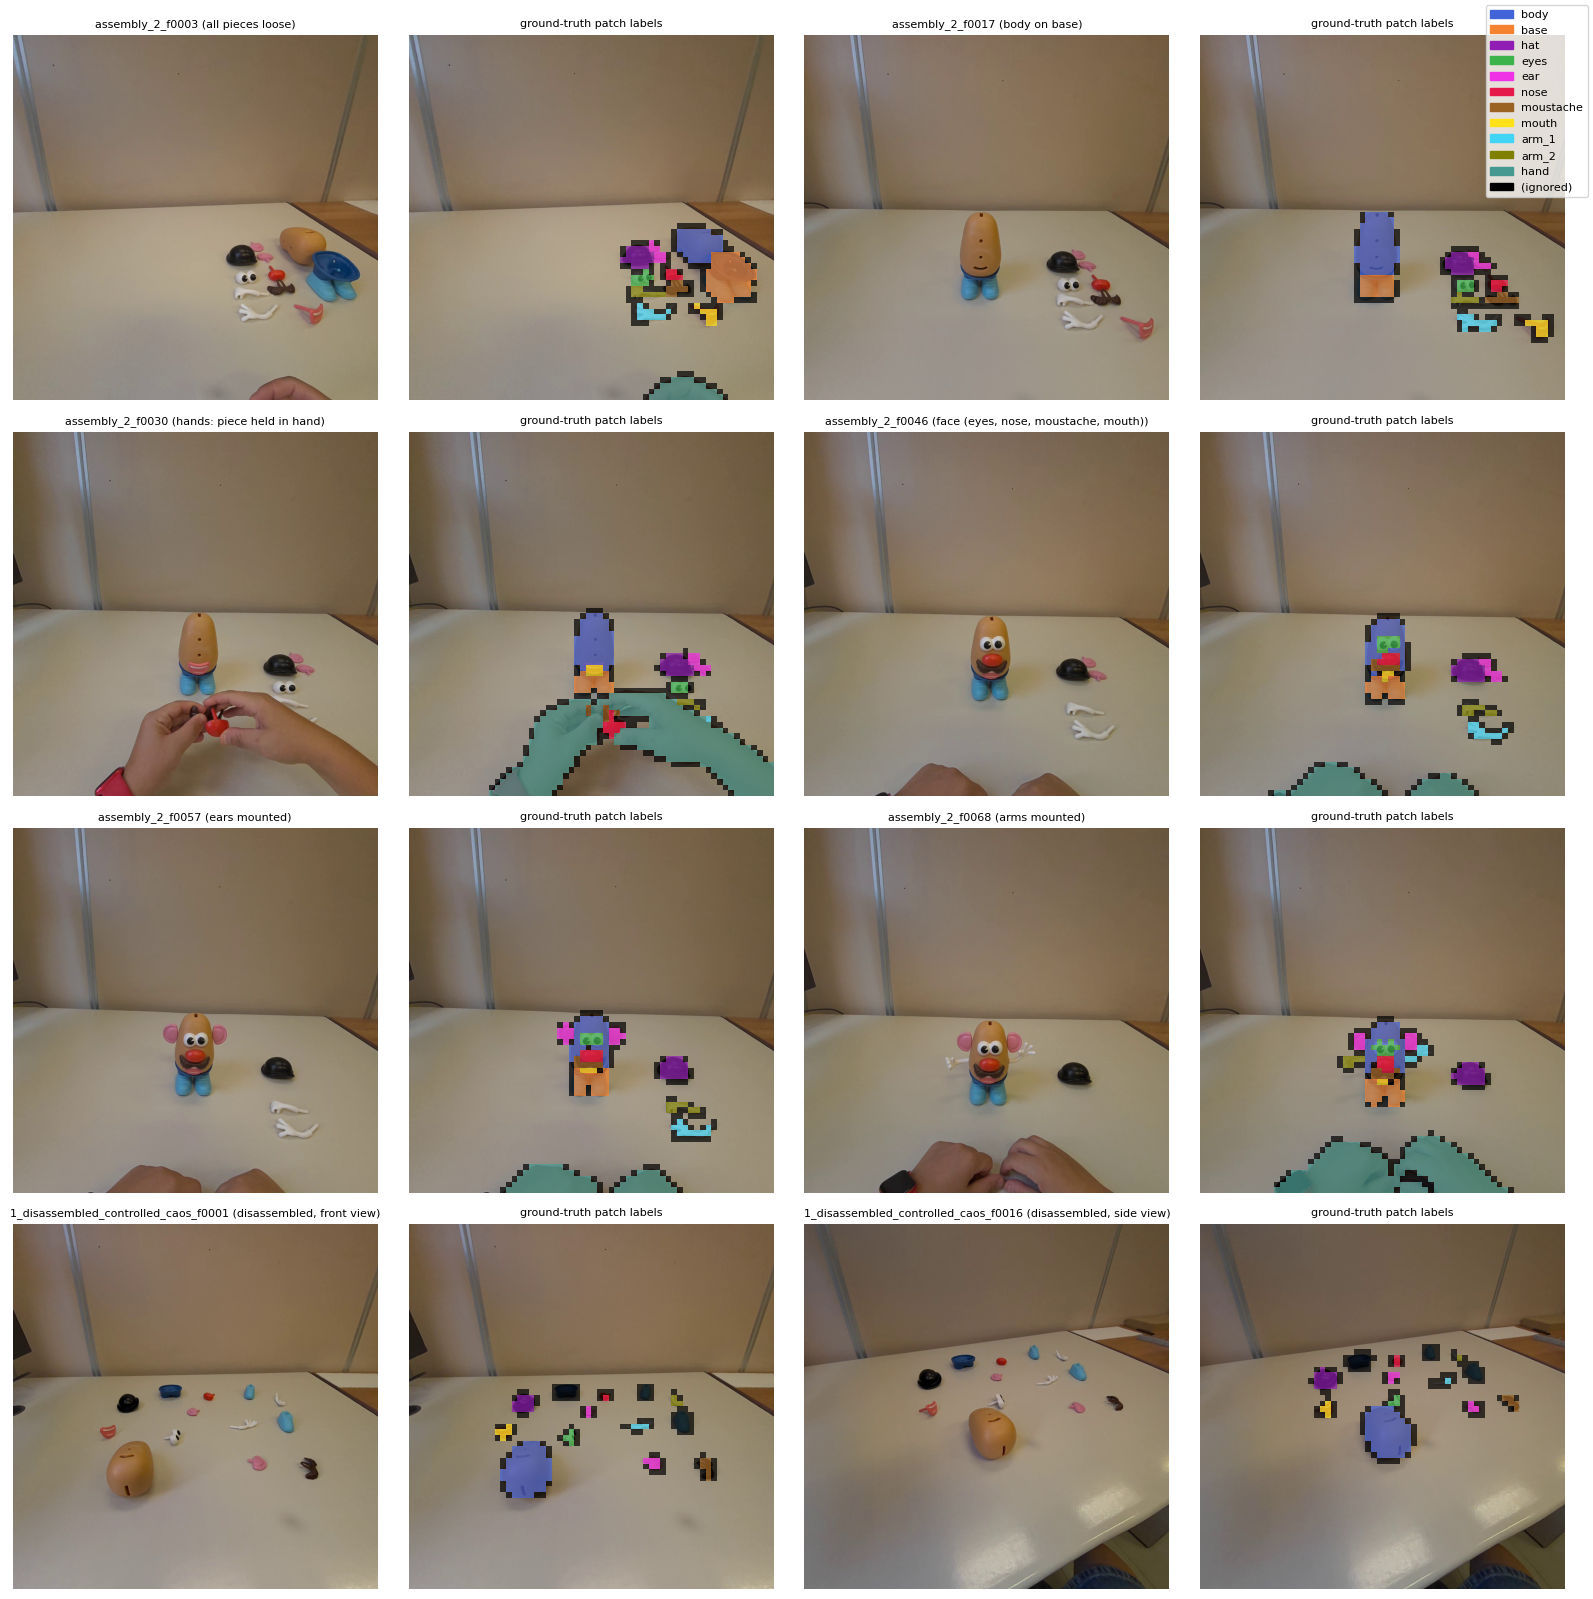

In [12]:
# 4.2 Ground-truth patch labels of the validation frames (same rules as the reference frames:
# majority >= MIN_LABEL_COVERAGE, mixed patches ignored). Background is left transparent.
for val in VALIDATION_FRAMES:
    image_path, json_path = frame_path(val["frame"]), frame_path(val["frame"], ".json")
    check_annotation(image_path, json_path)
    with Image.open(image_path) as img:
        val["resized_size"] = extractor.input_size(img.width, img.height)
    pixel_map = rasterize_annotation(json_path, GT_LABELS, val["resized_size"])
    val["pixel_map"] = pixel_map          # kept for the distance check (5.6)
    val["gt_labels"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for ax in axes.flat:
    ax.axis("off")
for (ax_image, ax_gt), val in zip(axes.reshape(-1, 2), VALIDATION_FRAMES):
    image = Image.open(frame_path(val["frame"])).convert("RGB").resize(val["resized_size"])
    alpha = np.where(val["gt_labels"] == 0, 0.0, 0.7)[..., None]
    ax_image.imshow(image)
    ax_image.set_title(f"{val['frame']} ({val['stage']})", fontsize=8)
    ax_gt.imshow(image)
    ax_gt.imshow(np.concatenate([label_grid_to_rgb(val["gt_labels"]), alpha], axis=-1),
                 extent=(0, image.width, image.height, 0), interpolation="nearest")
    ax_gt.set_title("ground-truth patch labels", fontsize=8)

legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES[1:]]
legend.append(mpatches.Patch(color="black", label="(ignored)"))
fig.legend(handles=legend, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_ground_truth.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 4.2: The ground-truth patch labels follow the objects in every frame, and boundary patches are ignored, as in the reference frames. Separated pants and shoes in 1_disassembled_controlled_caos are ignored. The jeans at the bottom of 1_disassembled_controlled_caos_f0016 are background, and the empty mouth slot in f0017 is body.

In [13]:
# 4.3 Ground-truth patches per class: how many patches each class IoU will rest on
gt_counts = pd.DataFrame({
    val["frame"]: {name: int((val["gt_labels"] == i).sum()) for i, name in enumerate(PATCH_LABEL_NAMES)}
    for val in VALIDATION_FRAMES
}).T
gt_counts.loc["total"] = gt_counts.sum()
display(gt_counts)

,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand,(ignored)
assembly_2_f0003,3779,39,62,18,8,7,5,8,8,10,8,36,108
assembly_2_f0017,3829,69,24,17,6,6,5,8,8,12,6,0,106
assembly_2_f0030,3430,56,21,19,6,8,10,6,6,1,4,412,117
assembly_2_f0046,3787,34,23,21,10,8,7,6,3,11,8,91,87
assembly_2_f0057,3786,32,24,18,8,15,8,6,3,11,8,90,87
assembly_2_f0068,3621,34,25,19,10,12,8,7,2,6,6,247,99
1_disassembled_controlled_caos_f0001,3879,67,0,11,4,7,1,6,5,3,3,0,110
1_disassembled_controlled_caos_f0016,3883,60,0,13,3,6,2,5,4,1,1,0,118
total,29994,391,179,136,55,69,46,52,39,55,44,876,832


Observation 4.3: The small pieces rest on few patches over the whole validation set: mouth 39, arm_2 44, nose 46, eyes 55, arm_1 55. Hand (876) and body (391) have the most. The two frames of 1_disassembled_controlled_caos contribute 1 to 7 patches per small piece, so the results on small pieces depend mostly on assembly_2. With so few patches, a handful of errors changes the IoU of a small piece noticeably.

832 patches are ignored, mostly piece boundaries.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

Russell et al. 2008, LabelMe, Sect. 3.3: overlapping polygons; an object completely contained in another one is on top.

Everingham et al. 2010, PASCAL VOC, Sect. 3.6.1: a 5-pixel void border around each object, labelled neither object nor background; Sect. 4.2.1: void pixels excluded from the evaluation.

Cordts et al. 2016, Cityscapes, Sect. 2.2: void label when a region is unclear, ignored in training and evaluation.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Metric and baseline

This section defines how a support set is measured, measures the baseline (the 7 reference frames of v1-baseline), and estimates how much the result could change by chance.

Each validation patch is compared with its ground truth. Per class, IoU = TP / (TP + FP + FN): unlike the fraction of correct patches, it also counts false positives, so a class predicted everywhere is penalized (Everingham et al. 2010, Sect. 4.2.1). The counts are summed over all frames before dividing, as in Cityscapes (Cordts et al. 2016, Sect. 3.1), and ignored patches do not count. The main number is the mIoU over the 10 pieces; background and hand are reported separately. Base is not evaluated in 1_disassembled_controlled_caos, where it is outside its definition.

Every result is given with margin 0 (pure nearest prototype) and with the provisional background margin of the pipeline (CONFIDENCE_MARGIN = 0.03, pipeline Section 9), so that the choice of the support set does not depend on the margin.

A secondary metric also ignores the background patches within one patch of any object (gt_tolerant), the same idea as the void border of PASCAL VOC (Everingham et al. 2010, Sect. 3.6.1) but one patch wide (16 px) instead of 5 px. Only background patches change, so errors between pieces are counted as in the main metric: the metric separates them from false positives right outside the pieces.

Eight frames are few, so the mIoU is given with a 95% bootstrap interval: the validation frames are resampled with replacement 1000 times, and the top and bottom 2.5% of the resampled values are dropped (Koehn 2004, Sect. 5). The same resamples are kept for every support set, so that later comparisons are paired.

5.1 extracts the validation features once, 5.2 gives the per-class IoU, 5.3 the confusion matrix, 5.4 the bootstrap intervals, 5.5 and 5.6 where the errors are.

In [14]:
# 5.1 Validation features, extracted once: every support set is then evaluated without running C-RADIO again
for val in VALIDATION_FRAMES:
    image = Image.open(frame_path(val["frame"])).convert("RGB")
    val["features"], _ = extractor.extract(image)
    val["excluded_ids"] = {CLASS_NAMES.index(name) for name in val.get("exclude", set())}
    val["gt_tolerant"] = ignore_boundary_ring(val["gt_labels"], BOUNDARY_RING)
EXCLUDED = [val["excluded_ids"] for val in VALIDATION_FRAMES]


def evaluate(prototype_matrix, margin, gt_key="gt_labels"):
    """Per-frame confusion matrices of one set of prototypes on the validation frames.
    gt_key: "gt_labels" (main metric) or "gt_tolerant" (boundary ring ignored)."""
    return [confusion_matrix(val[gt_key], classify_patches(val["features"], prototype_matrix, margin)[0])
            for val in VALIDATION_FRAMES]

In [15]:
# 5.2 Per-class IoU of the baseline support set (7 frames), accumulated over the 8 validation frames.
# Main metric (gt_labels) and secondary metric with the boundary ring ignored (gt_tolerant).
baseline_results = {}
for gt_key in ["gt_labels", "gt_tolerant"]:
    for margin in EVAL_MARGINS:
        confusions = evaluate(prototype_matrix, margin, gt_key)
        baseline_results[(gt_key, margin)] = {"confusions": confusions,
                                              "iou": iou_from_confusions(confusions, EXCLUDED)}

iou_table = pd.DataFrame({f"{gt_key}, margin {m:.2f}": r["iou"] for (gt_key, m), r in baseline_results.items()},
                         index=CLASS_NAMES)
iou_table.loc["mIoU (10 pieces)"] = [mean_iou(r["iou"]) for r in baseline_results.values()]
display(iou_table.round(3))

,"gt_labels, margin 0.00","gt_labels, margin 0.03","gt_tolerant, margin 0.00","gt_tolerant, margin 0.03"
background,0.984,0.991,0.996,0.997
body,0.701,0.760,0.829,0.865
base,0.771,0.818,0.941,0.946
hat,0.819,0.889,1.000,1.000
eyes,0.590,0.598,0.636,0.636
ear,0.489,0.622,0.802,0.831
nose,0.544,0.597,0.672,0.672
moustache,0.692,0.763,0.789,0.789
mouth,0.313,0.313,0.313,0.313
arm_1,0.731,0.754,0.790,0.790


Observation 5.2: Baseline support set (7 frames) on the 8 validation frames. The mIoU over the 10 pieces is 0.594 without margin and 0.648 with margin 0.03. Hat (0.889), base (0.818), moustache (0.763), body (0.760) and arm_1 (0.754) are the best pieces. Mouth (0.313) and arm_2 (0.363) are the worst, followed by nose (0.597), eyes (0.598) and ear (0.622).

The margin raises almost every piece, most of all ear (0.489 to 0.622), hat, moustache, arm_2 and body; eyes barely change and mouth not at all.

With the boundary ring ignored (gt_tolerant), the mIoU rises to 0.747 without margin and 0.757 with margin 0.03. arm_2 (0.363 to 0.725), ear (0.622 to 0.831), hat (1.000), base (0.946) and body (0.865) gain the most: much of their error is just outside the pieces. Mouth (0.313, unchanged), eyes (0.636), nose (0.672), moustache (0.789) and arm_1 (0.790) change less: more of their error is between pieces. With the ring ignored, the margin adds only 0.010.

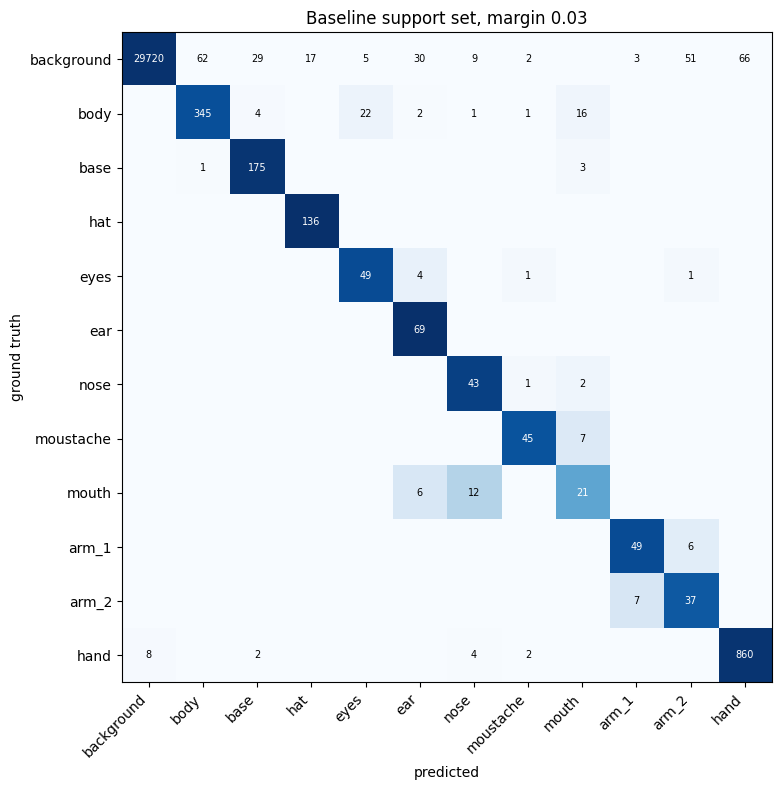

In [16]:
# 5.3 Confusion matrix of the baseline (margin CONFIDENCE_MARGIN), summed over the 8 validation frames.
# Rows: ground truth, columns: prediction. Numbers are patch counts; color is the fraction of the row.
# Note: all frames are summed here, including base in 1_disassembled_controlled_caos (excluded from the IoU).
total = np.sum(baseline_results[("gt_labels", CONFIDENCE_MARGIN)]["confusions"], axis=0)
row_fraction = total / np.maximum(total.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(row_fraction, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if total[i, j]:
            ax.text(j, i, total[i, j], ha="center", va="center", fontsize=7,
                    color="white" if row_fraction[i, j] > 0.5 else "black")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("ground truth")
ax.set_title(f"Baseline support set, margin {CONFIDENCE_MARGIN}")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "baseline_confusion.png", dpi=120, bbox_inches="tight")
plt.show()

Observation 5.3: No piece patch is predicted as background. The errors are of two kinds. 274 background patches are predicted as a piece or hand: body 62, hand 66, arm_2 51, ear 30, base 29, and fewer for the others. The rest are confusions between pieces.

Mouth patches go to nose (12) and ear (6); body patches go to eyes (22) and mouth (16); moustache patches go to mouth (7); eyes patches go to ear (4). Between the arms, 7 arm_2 patches are predicted as arm_1 and 6 arm_1 patches as arm_2, while arm_2 also takes 51 background patches. All 69 ear patches are correct: ear loses IoU only through false positives.

In [17]:
# 5.4 Uncertainty of the mIoU: bootstrap over the validation frames (resampled with replacement).
# The same resamples are used for every support set, so later comparisons are paired.
rng = np.random.default_rng(RANDOM_SEED)
BOOTSTRAP_INDICES = rng.integers(0, len(VALIDATION_FRAMES), size=(N_BOOTSTRAP, len(VALIDATION_FRAMES)))


def bootstrap_miou(confusions):
    """mIoU on each bootstrap resample of the validation frames."""
    return np.array([mean_iou(iou_from_confusions([confusions[i] for i in idx], [EXCLUDED[i] for i in idx]))
                     for idx in BOOTSTRAP_INDICES])


for (gt_key, margin), r in baseline_results.items():
    r["bootstrap"] = bootstrap_miou(r["confusions"])
    low, high = np.percentile(r["bootstrap"], [2.5, 97.5])
    print(f"{gt_key}, margin {margin:.2f}: mIoU {mean_iou(r['iou']):.3f}, 95% bootstrap interval [{low:.3f}, {high:.3f}]")

gt_labels, margin 0.00: mIoU 0.594, 95% bootstrap interval [0.551, 0.649]
gt_labels, margin 0.03: mIoU 0.648, 95% bootstrap interval [0.602, 0.700]
gt_tolerant, margin 0.00: mIoU 0.747, 95% bootstrap interval [0.705, 0.795]
gt_tolerant, margin 0.03: mIoU 0.757, 95% bootstrap interval [0.716, 0.800]


In [18]:
# 5.4 (continued) Are 1000 resamples enough? Same bootstrap with 5 different seeds: the interval should barely move
key = ("gt_labels", CONFIDENCE_MARGIN)
for seed in range(1, 6):
    idx = np.random.default_rng(seed).integers(0, len(VALIDATION_FRAMES), size=(N_BOOTSTRAP, len(VALIDATION_FRAMES)))
    values = np.array([mean_iou(iou_from_confusions([baseline_results[key]["confusions"][i] for i in row],
                                                    [EXCLUDED[i] for i in row])) for row in idx])
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"seed {seed}: [{low:.3f}, {high:.3f}]")

seed 1: [0.596, 0.702]
seed 2: [0.597, 0.704]
seed 3: [0.601, 0.703]
seed 4: [0.597, 0.700]
seed 5: [0.601, 0.703]


Observation 5.4: 95% bootstrap intervals over the validation frames: main metric [0.551, 0.649] without margin and [0.602, 0.700] with margin 0.03; boundary ring ignored [0.705, 0.795] and [0.716, 0.800]. The intervals are about ±0.05 wide, so a support set cannot be judged better from a small difference in mIoU. Comparisons between support sets will use the same resamples (paired).

Repeating the bootstrap with 5 other seeds (main metric, margin 0.03) moves the interval bounds by at most 0.006 (lower, 0.596–0.602) and 0.004 (upper, 0.700–0.704), against an interval width of about 0.10: 1000 resamples are enough.

Limitation: 6 of the 8 validation frames come from the same sequence and are correlated, so the intervals are likely narrower than with independent frames.

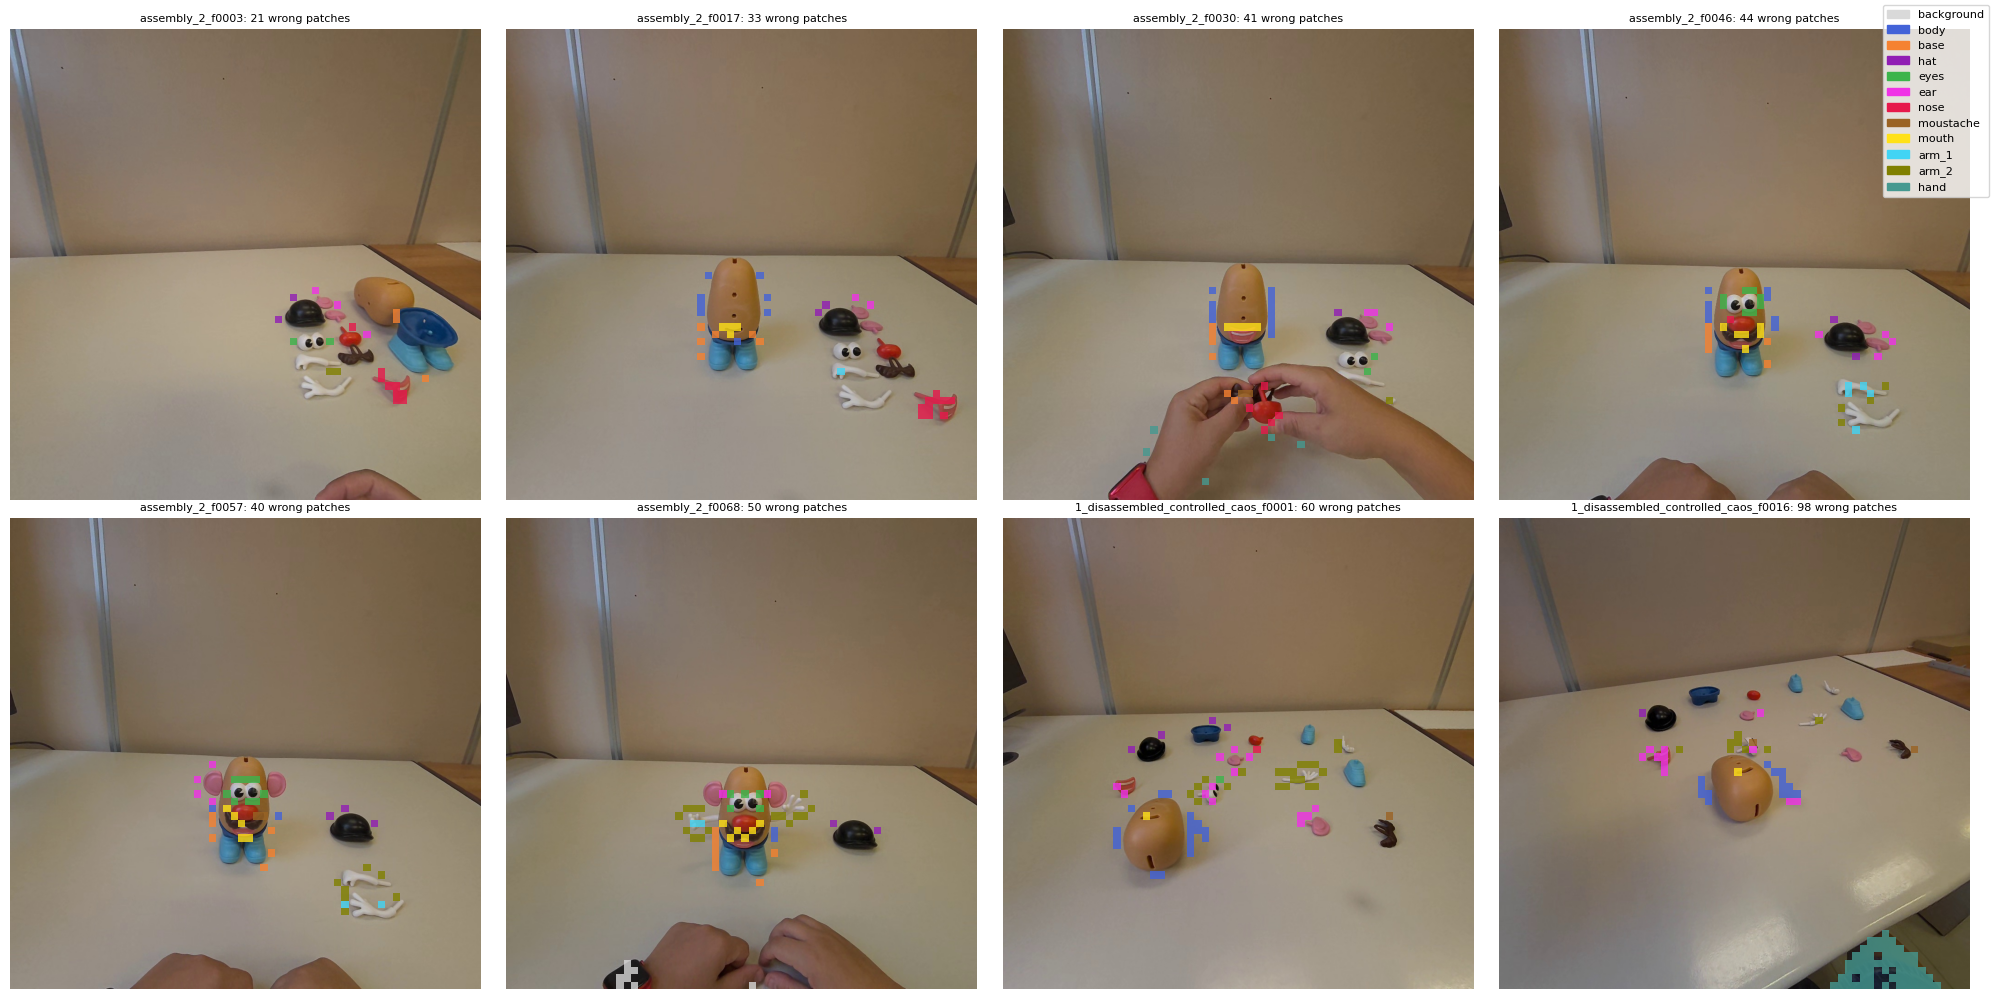

In [19]:
# 5.5 Where the baseline is wrong (margin CONFIDENCE_MARGIN): wrong patches colored by the predicted class.
# Correct and ignored patches are transparent.
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, val in zip(axes.flat, VALIDATION_FRAMES):
    pred = classify_patches(val["features"], prototype_matrix, CONFIDENCE_MARGIN)[0]
    wrong = (val["gt_labels"] != IGNORE_ID) & (pred != val["gt_labels"])
    image = Image.open(frame_path(val["frame"])).convert("RGB").resize(val["resized_size"])
    ax.imshow(image)
    ax.imshow(np.concatenate([label_grid_to_rgb(pred), 0.8 * wrong[..., None]], axis=-1),
              extent=(0, image.width, image.height, 0), interpolation="nearest")
    ax.set_title(f"{val['frame']}: {wrong.sum()} wrong patches", fontsize=8)
    ax.axis("off")

legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES]
fig.legend(handles=legend, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "baseline_errors.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 5.5:
Most false positives lie right outside the pieces: background patches next to a piece are predicted as that piece (body sides, base, ears, hat, around mounted eyes, both sides of the mounted and loose arms). The 51 background patches predicted as arm_2 are of this kind. Jeans at the bottom of 1_disassembled_controlled_caos_f0016 are predicted as hand, the largest single error (98 wrong patches in that frame). Errors between pieces are few and localized: a mouth lying on its side predicted as nose (f0003, f0017), the empty mouth slot predicted as mouth (f0017), mouth and nose alternating on the face (f0068), some arm_1 patches on loose arms.

In [20]:
# 5.6 Background patches predicted as a piece: how far are they from an annotated object?
# Two distances, in pixels at model-input resolution, from the patch to the nearest pixel of:
#   - the predicted class ("distance (px)")
#   - any annotated or ignored object ("distance to any object (px)")
# A background patch next to the ignored boundary ring is at 1-15 px; 1e9 means the class is not annotated in the frame.
rows = []
for val in VALIDATION_FRAMES:
    pred = classify_patches(val["features"], prototype_matrix, CONFIDENCE_MARGIN)[0]
    false_positive = (val["gt_labels"] == 0) & (pred != 0)
    h, w = pred.shape

    distance_any = ndimage.distance_transform_edt(val["pixel_map"] == 0)
    patch_distance_any = (distance_any[:h * PATCH_SIZE, :w * PATCH_SIZE]
                          .reshape(h, PATCH_SIZE, w, PATCH_SIZE).min(axis=(1, 3)))

    for class_id in np.unique(pred[false_positive]):
        if (val["pixel_map"] == class_id).any():
            distance = ndimage.distance_transform_edt(val["pixel_map"] != class_id)
            patch_distance = (distance[:h * PATCH_SIZE, :w * PATCH_SIZE]
                              .reshape(h, PATCH_SIZE, w, PATCH_SIZE).min(axis=(1, 3)))
        else:
            patch_distance = np.full((h, w), 1e9)          # class not annotated in this frame

        mask = false_positive & (pred == class_id)
        for d, d_any in zip(patch_distance[mask], patch_distance_any[mask]):
            rows.append({"frame": val["frame"], "predicted": CLASS_NAMES[class_id],
                         "distance (px)": d, "distance to any object (px)": d_any})

distances = pd.DataFrame(rows)
bins = [0, 4, 8, 16, 32, np.inf]
range_labels = ["0-3", "4-7", "8-15", "16-31", "32+ or absent"]
distances["range (same class)"] = pd.cut(distances["distance (px)"], bins=bins, right=False, labels=range_labels)
distances["range (any object)"] = pd.cut(distances["distance to any object (px)"], bins=bins, right=False,
                                         labels=range_labels)

print(f"{len(distances)} background patches predicted as a piece")
display(pd.crosstab(distances["predicted"], distances["range (same class)"], margins=True))
display(pd.crosstab(distances["predicted"], distances["range (any object)"], margins=True))

274 background patches predicted as a piece


range (same class),0-3,4-7,8-15,16-31,32+ or absent,All
predicted,,,,,,
arm_1,3,0,0,0,0,3
arm_2,8,7,3,3,30,51
base,12,10,7,0,0,29
body,18,20,15,6,3,62
ear,12,7,4,0,7,30
eyes,4,1,0,0,0,5
hand,4,1,0,0,61,66
hat,10,5,0,0,2,17
moustache,2,0,0,0,0,2


range (any object),0-3,4-7,8-15,16-31,32+ or absent,All
predicted,,,,,,
arm_1,3,0,0,0,0,3
arm_2,18,21,12,0,0,51
base,12,12,5,0,0,29
body,18,20,15,6,3,62
ear,13,11,4,1,1,30
eyes,4,1,0,0,0,5
hand,4,1,0,0,61,66
hat,11,6,0,0,0,17
moustache,2,0,0,0,0,2


Observation 5.6: 201 of the 274 background patches predicted as a piece lie within 15 px of an annotated object, that is, in the first patch beyond the ignored boundary. Only 88 lie within 3 px, so polygons a few pixels too tight could explain at most a third of them. 65 lie far from any object: 61 are the jeans predicted as hand in 1_disassembled_controlled_caos_f0016.

All 51 background patches predicted as arm_2 lie next to an object, but 30 of them are more than 32 px from any arm_2 pixel: arm_2 takes the boundary of other pieces. The same happens, less often, for nose (6 of 9) and ear (7 of 30).

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Everingham et al. 2010, PASCAL VOC, Sect. 4.2.1, Eq. (4): per-class IoU = TP / (TP + FP + FN), void excluded; the fraction of correct pixels is misleading. Sect. 3.6.1: the void border, the idea behind the secondary metric.

Cordts et al. 2016, Cityscapes, Sect. 3.1: TP, FP and FN counted over the whole evaluation set.

Koehn 2004, Sect. 5: bootstrap percentile interval (resampling with replacement, 1000 resamples, top and bottom 2.5% dropped).

------------------------------------------------------------------------------------------------------------------------------------------


## Section 6 - Targeted additions

This section tests candidate reference frames, each chosen for an error between pieces found in Section 5. Candidates come only from sequences never used for evaluation. Hands are annotated in the candidates but not used, so the hand prototype stays as in the baseline.

Each candidate is first added alone to the baseline support set (6.2). Every change is measured with a paired comparison: the mIoU difference is computed on the same bootstrap resamples as the baseline, as in paired bootstrap resampling (Koehn 2004, Sect. 6). A candidate counts as an improvement only if the 95% interval of the difference is entirely above zero, that is, if it is better in at least 97.5% of the resamples.

The results in 6.2 are dominated by swaps between arm_1 and arm_2, which change direction with every candidate (6.3). For this reason, after 6.2 and 6.3 the arms were merged into one class for the selection (6.4): the choice between the two arms is left to an object-level decision in Phase 2. This decision was taken after seeing the results; the selection rule of 6.5 was then fixed before running it. The main metric over the 10 pieces is still reported.

6.5 selects frames with a greedy forward selection, 6.6 checks which baseline frames are needed, 6.7 compares the selected support set with the baseline, and 6.8 repeats the comparison with the center-pixel labelling rule.

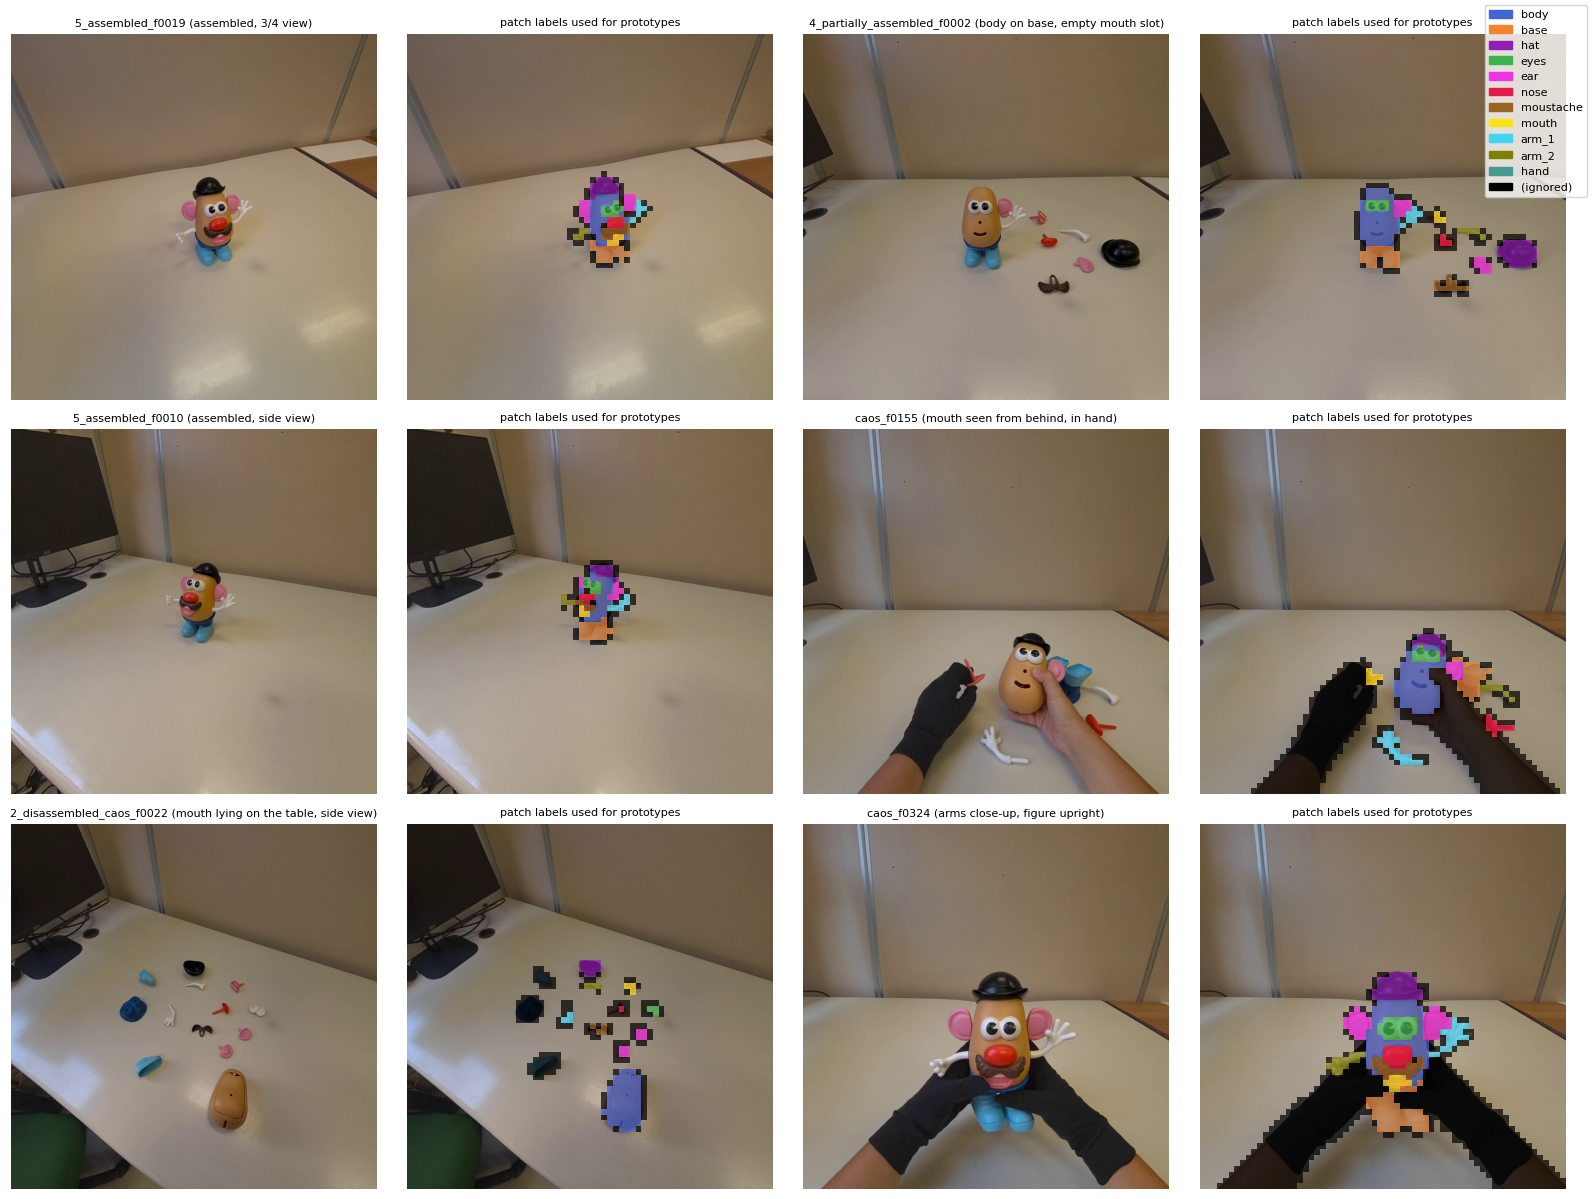

,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
5_assembled_f0019,3954,25,17,14,8,13,6,8,4,5,4,0
4_partially_assembled_f0002,3863,51,23,29,8,15,3,10,3,7,5,0
5_assembled_f0010,3979,23,17,8,6,7,4,4,3,6,3,0
caos_f0155,3442,66,26,12,11,8,9,0,6,17,6,0
2_disassembled_caos_f0022,3867,59,0,10,3,8,1,4,3,3,3,0
caos_f0324,3207,70,52,36,25,41,18,18,10,18,14,0
baseline support set (7 frames),26744,226,184,38,24,39,23,27,20,28,11,482


In [31]:
# 6.1 Candidate reference frames: features and patch labels, same rules as the baseline reference frames.
# Ignored patches (black) include boundaries, unused labels (hands) and legacy labels.
for cand in CANDIDATE_FRAMES:
    image_path, json_path = frame_path(cand["frame"]), frame_path(cand["frame"], ".json")
    check_annotation(image_path, json_path)
    cand["features"], cand["resized_size"] = extractor.extract(Image.open(image_path).convert("RGB"))
    pixel_map = rasterize_annotation(json_path, cand["use_labels"], cand["resized_size"])
    cand["patch_labels"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax in axes.flat:
    ax.axis("off")
for (ax_image, ax_labels), cand in zip(axes.reshape(-1, 2), CANDIDATE_FRAMES):
    image = Image.open(frame_path(cand["frame"])).convert("RGB").resize(cand["resized_size"])
    alpha = np.where(cand["patch_labels"] == 0, 0.0, 0.7)[..., None]
    ax_image.imshow(image)
    ax_image.set_title(f"{cand['frame']} ({cand['role']})", fontsize=8)
    ax_labels.imshow(image)
    ax_labels.imshow(np.concatenate([label_grid_to_rgb(cand["patch_labels"]), alpha], axis=-1),
                     extent=(0, image.width, image.height, 0), interpolation="nearest")
    ax_labels.set_title("patch labels used for prototypes", fontsize=8)
legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES[1:]]
legend.append(mpatches.Patch(color="black", label="(ignored)"))
fig.legend(handles=legend, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "candidate_patch_labels.png", dpi=100, bbox_inches="tight")
plt.show()

candidate_counts = pd.DataFrame({
    cand["frame"]: {name: int((cand["patch_labels"] == i).sum()) for i, name in enumerate(CLASS_NAMES)}
    for cand in CANDIDATE_FRAMES
}).T
candidate_counts.loc["baseline support set (7 frames)"] = [patch_counts.get(name, 0) for name in CLASS_NAMES]
display(candidate_counts)

Observation 6.1: Six candidates, from sequences never used for evaluation, each chosen for an error found in Section 5: the assembled figure in 3/4 view (5_assembled_f0019) and side view (5_assembled_f0010), the body on the base with the empty mouth slot (4_partially_assembled_f0002), the mouth seen from behind and held in hand (caos_f0155), the mouth lying on the table seen from the side (2_disassembled_caos_f0022), and a close-up of the upright figure (caos_f0324). caos_f0324 alone has about as many eye, ear and arm_2 patches as the whole baseline support set.

The candidates aimed at a specific error bring few patches of that class: 3 mouth patches in 2_disassembled_caos_f0022 and 6 in caos_f0155, against 20 in the baseline mouth prototype, while the empty mouth slot of 4_partially_assembled_f0002 is part of the 51 body patches. With one patch-weighted mean per class, a rare appearance brought by a few patches moves the prototype only slightly.

In [32]:
# 6.2 Targeted additions: baseline support set + one candidate at a time.
# delta = mIoU with the candidate minus baseline mIoU. The 95% interval of delta is computed on the
# same bootstrap resamples as the baseline (paired comparison).
KEY_CLASSES = ["mouth", "nose", "eyes", "arm_1", "arm_2"]


def run_support_set(reference_frames):
    """Build prototypes from reference_frames and evaluate them with every metric and margin."""
    prototypes, counts = build_prototypes(reference_frames)
    matrix = stack_prototypes(prototypes)
    results = {}
    for gt_key in ["gt_labels", "gt_tolerant"]:
        for margin in EVAL_MARGINS:
            confusions = evaluate(matrix, margin, gt_key)
            results[(gt_key, margin)] = {"confusions": confusions,
                                         "iou": iou_from_confusions(confusions, EXCLUDED),
                                         "bootstrap": bootstrap_miou(confusions)}
    return results, counts


rows, addition_results = [], {}
for cand in CANDIDATE_FRAMES:
    results, _ = run_support_set(BASELINE_REFERENCE_FRAMES + [cand])
    addition_results[cand["frame"]] = results
    for (gt_key, margin), r in results.items():
        base = baseline_results[(gt_key, margin)]
        low, high = np.percentile(r["bootstrap"] - base["bootstrap"], [2.5, 97.5])
        row = {"candidate": cand["frame"], "metric": gt_key, "margin": margin,
               "mIoU": mean_iou(r["iou"]), "delta": mean_iou(r["iou"]) - mean_iou(base["iou"]),
               "delta low": low, "delta high": high}
        row.update({f"d {c}": r["iou"][CLASS_NAMES.index(c)] - base["iou"][CLASS_NAMES.index(c)] for c in KEY_CLASSES})
        rows.append(row)

additions = pd.DataFrame(rows)
for margin in EVAL_MARGINS:
    print(f"Margin {margin:.2f}")
    display(additions[additions["margin"] == margin].drop(columns="margin").round(3))

Margin 0.00


,candidate,metric,mIoU,delta,delta low,delta high,d mouth,d nose,d eyes,d arm_1,d arm_2
0,5_assembled_f0019,gt_labels,0.612,0.017,-0.017,0.048,0.112,0.149,0.030,-0.124,-0.105
2,5_assembled_f0019,gt_tolerant,0.726,-0.021,-0.062,0.024,0.112,0.057,0.026,-0.128,-0.275
4,4_partially_assembled_f0002,gt_labels,0.580,-0.015,-0.041,0.012,0.081,0.010,0.030,-0.187,-0.068
6,4_partially_assembled_f0002,gt_tolerant,0.730,-0.017,-0.043,0.010,0.081,-0.011,0.026,-0.184,-0.139
8,5_assembled_f0010,gt_labels,0.615,0.021,-0.004,0.041,0.042,0.133,0.007,-0.019,-0.033
10,5_assembled_f0010,gt_tolerant,0.751,0.003,-0.025,0.033,0.042,0.074,0.008,-0.026,-0.078
12,caos_f0155,gt_labels,0.598,0.004,-0.024,0.028,0.054,-0.162,0.015,0.002,-0.084
14,caos_f0155,gt_tolerant,0.735,-0.012,-0.046,0.022,0.054,-0.145,0.008,-0.057,-0.098
16,2_disassembled_caos_f0022,gt_labels,0.604,0.010,-0.008,0.028,0.030,0.021,0.000,0.046,0.026
18,2_disassembled_caos_f0022,gt_tolerant,0.762,0.015,-0.010,0.042,0.030,0.011,0.000,0.040,0.057


Margin 0.03


,candidate,metric,mIoU,delta,delta low,delta high,d mouth,d nose,d eyes,d arm_1,d arm_2
1,5_assembled_f0019,gt_labels,0.658,0.011,-0.025,0.047,0.112,0.108,0.039,-0.124,-0.136
3,5_assembled_f0019,gt_tolerant,0.737,-0.020,-0.060,0.026,0.112,0.070,0.026,-0.128,-0.285
5,4_partially_assembled_f0002,gt_labels,0.632,-0.015,-0.040,0.011,0.081,-0.003,0.039,-0.185,-0.083
7,4_partially_assembled_f0002,gt_tolerant,0.740,-0.016,-0.043,0.012,0.081,-0.011,0.026,-0.184,-0.158
9,5_assembled_f0010,gt_labels,0.667,0.020,-0.002,0.039,0.042,0.101,0.015,-0.000,-0.053
11,5_assembled_f0010,gt_tolerant,0.761,0.004,-0.025,0.036,0.042,0.074,0.008,-0.026,-0.080
13,caos_f0155,gt_labels,0.640,-0.008,-0.036,0.018,0.054,-0.154,0.007,-0.021,-0.103
15,caos_f0155,gt_tolerant,0.747,-0.009,-0.045,0.026,0.054,-0.130,0.008,-0.057,-0.096
17,2_disassembled_caos_f0022,gt_labels,0.657,0.009,-0.008,0.029,0.030,0.008,0.000,0.036,0.022
19,2_disassembled_caos_f0022,gt_tolerant,0.770,0.013,-0.013,0.040,0.030,0.011,0.000,0.040,0.044


Observation 6.2 (margin 0.03): With the 10 pieces, no single addition gives a paired 95% interval entirely above zero. Mouth improves with every candidate (+0.030 to +0.112). Nose improves with 5_assembled_f0019, 5_assembled_f0010 and caos_f0324 (+0.10 to +0.18) and drops with caos_f0155 (−0.154).

The arms drop with almost every candidate (arm_1 down to −0.185, arm_2 down to −0.165), also with the boundary ring ignored. 2_disassembled_caos_f0022 is the only candidate that raises both arms.

In [33]:
# 6.3 Arms: similarity between the arm prototypes and arm confusions, for the baseline and each addition
# (main metric, margin CONFIDENCE_MARGIN, summed over the validation frames)
ARM_1, ARM_2 = CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")
OTHER_PIECES = [i for i in range(len(CLASS_NAMES)) if i not in (0, ARM_1, ARM_2)]


def arm_diagnostics(reference_frames, confusions):
    prototypes, _ = build_prototypes(reference_frames)
    total = np.sum(confusions, axis=0)
    return {"cos(arm_1, arm_2)": float(prototypes["arm_1"] @ prototypes["arm_2"]),
            "arm_1 correct": int(total[ARM_1, ARM_1]), "arm_2 correct": int(total[ARM_2, ARM_2]),
            "arm_1 -> arm_2": int(total[ARM_1, ARM_2]), "arm_2 -> arm_1": int(total[ARM_2, ARM_1]),
            "arms -> other pieces": int(total[[ARM_1, ARM_2]][:, OTHER_PIECES].sum()),
            "other pieces -> arms": int(total[OTHER_PIECES][:, [ARM_1, ARM_2]].sum())}


key = ("gt_labels", CONFIDENCE_MARGIN)
arm_rows = {"baseline": arm_diagnostics(BASELINE_REFERENCE_FRAMES, baseline_results[key]["confusions"])}
for cand in CANDIDATE_FRAMES:
    arm_rows[cand["frame"]] = arm_diagnostics(BASELINE_REFERENCE_FRAMES + [cand],
                                              addition_results[cand["frame"]][key]["confusions"])
display(pd.DataFrame(arm_rows).T.round(3))

,"cos(arm_1, arm_2)",arm_1 correct,arm_2 correct,arm_1 -> arm_2,arm_2 -> arm_1,arms -> other pieces,other pieces -> arms
baseline,0.950,49.0,37.0,6.0,7.0,0.0,1.0
5_assembled_f0019,0.955,51.0,22.0,4.0,22.0,0.0,2.0
4_partially_assembled_f0002,0.934,37.0,38.0,18.0,6.0,0.0,5.0
5_assembled_f0010,0.958,52.0,31.0,3.0,13.0,0.0,1.0
caos_f0155,0.936,44.0,39.0,11.0,5.0,0.0,7.0
2_disassembled_caos_f0022,0.949,49.0,40.0,6.0,4.0,0.0,2.0
caos_f0324,0.956,53.0,17.0,2.0,27.0,0.0,6.0


Observation 6.3: The cosine between the arm_1 and arm_2 prototypes stays between 0.934 and 0.958 with every addition (0.950 in the baseline). Arm patches are never predicted as other pieces, and only 1 to 7 patches of other pieces are predicted as arms. The swaps between the two arms change direction with the candidate. With both arms mounted in the candidate (5_assembled_f0019, 5_assembled_f0010, caos_f0324), arm_2 patches predicted as arm_1 grow from 7 to 22, 13 and 27. With one arm mounted and one loose (4_partially_assembled_f0002, caos_f0155), arm_1 patches predicted as arm_2 grow from 6 to 18 and 11. Small changes of the prototypes move tens of patches from one arm to the other.

Hypothesis (supported by the data above): the two arms are made of the same white plastic. Mounted, they look different, but from some viewpoints, especially loose on the table, they differ only in the hand, which covers few patches. Most arm patches then look almost the same, so the choice between arm_1 and arm_2 depends on very small differences between the prototypes, and any added frame moves the boundary.

In [34]:
# 6.4 Arms merged: arm_1 and arm_2 counted as one class "arm" in the metric (the classifier still predicts both).
# A patch of one arm predicted as the other counts as correct. This metric is used for the selection in 6.5 and 6.6.
MERGED_NAMES = ["arm" if name == "arm_1" else name for name in CLASS_NAMES if name != "arm_2"]
MERGED_PIECES = (PIECE_LABELS - {"arm_1", "arm_2"}) | {"arm"}
KEEP = [i for i in range(len(CLASS_NAMES)) if i != ARM_2]


def merge_arms(confusion):
    merged = confusion.copy()
    merged[ARM_1, :] += merged[ARM_2, :]
    merged[:, ARM_1] += merged[:, ARM_2]
    return merged[np.ix_(KEEP, KEEP)]


def miou_merged(confusions, idx=None):
    idx = range(len(confusions)) if idx is None else idx
    iou = iou_from_confusions([merge_arms(confusions[i]) for i in idx], [EXCLUDED[i] for i in idx])
    return mean_iou(iou, MERGED_NAMES, MERGED_PIECES), iou


for gt_key in ["gt_labels", "gt_tolerant"]:
    key = (gt_key, CONFIDENCE_MARGIN)
    base_conf = baseline_results[key]["confusions"]
    base_miou, base_iou = miou_merged(base_conf)
    base_boot = np.array([miou_merged(base_conf, idx)[0] for idx in BOOTSTRAP_INDICES])
    rows = []
    for cand in CANDIDATE_FRAMES:
        conf = addition_results[cand["frame"]][key]["confusions"]
        cand_miou, cand_iou = miou_merged(conf)
        boot = np.array([miou_merged(conf, idx)[0] for idx in BOOTSTRAP_INDICES])
        low, high = np.percentile(boot - base_boot, [2.5, 97.5])
        rows.append({"candidate": cand["frame"], "mIoU": cand_miou, "delta": cand_miou - base_miou,
                     "delta low": low, "delta high": high,
                     "d arm": cand_iou[MERGED_NAMES.index("arm")] - base_iou[MERGED_NAMES.index("arm")],
                     "d mouth": cand_iou[MERGED_NAMES.index("mouth")] - base_iou[MERGED_NAMES.index("mouth")],
                     "d nose": cand_iou[MERGED_NAMES.index("nose")] - base_iou[MERGED_NAMES.index("nose")]})
    print(f"{gt_key}, margin {CONFIDENCE_MARGIN}, arms merged: baseline mIoU {base_miou:.3f}")
    display(pd.DataFrame(rows).round(3))

gt_labels, margin 0.03, arms merged: baseline mIoU 0.667


,candidate,mIoU,delta,delta low,delta high,d arm,d mouth,d nose
0,5_assembled_f0019,0.709,0.042,0.025,0.059,0.008,0.112,0.108
1,4_partially_assembled_f0002,0.670,0.003,-0.016,0.026,-0.084,0.081,-0.003
2,5_assembled_f0010,0.695,0.028,0.020,0.035,0.004,0.042,0.101
3,caos_f0155,0.657,-0.010,-0.036,0.016,-0.133,0.054,-0.154
4,2_disassembled_caos_f0022,0.670,0.003,-0.004,0.012,-0.008,0.030,0.008
5,caos_f0324,0.700,0.033,-0.012,0.075,0.017,0.112,0.178


gt_tolerant, margin 0.03, arms merged: baseline mIoU 0.783


,candidate,mIoU,delta,delta low,delta high,d arm,d mouth,d nose
0,5_assembled_f0019,0.805,0.023,0.007,0.042,-0.010,0.112,0.070
1,4_partially_assembled_f0002,0.798,0.015,-0.005,0.035,-0.038,0.081,-0.011
2,5_assembled_f0010,0.798,0.016,0.007,0.027,0.000,0.042,0.074
3,caos_f0155,0.783,0.000,-0.022,0.021,-0.056,0.054,-0.130
4,2_disassembled_caos_f0022,0.786,0.004,-0.005,0.015,-0.010,0.030,0.011
5,caos_f0324,0.787,0.004,-0.046,0.045,-0.065,0.112,0.120


Observation 6.4: With arm_1 and arm_2 counted as one class, two candidates improve the mIoU with the paired 95% interval entirely above zero: 5_assembled_f0019 (+0.042, [0.025, 0.059]) and 5_assembled_f0010 (+0.028, [0.020, 0.035]), also with the boundary ring ignored (+0.023 and +0.016). Their gain comes from mouth and nose; the merged arm class does not change.

caos_f0324 improves mouth and nose, but its interval includes zero. 4_partially_assembled_f0002 and 2_disassembled_caos_f0022 have no measurable effect. caos_f0155 lowers nose (−0.154) and arm (−0.133).

The merged metric was introduced after 6.2 and 6.3, so it is a choice made on the validation results; the reason is the instability of the arm swaps shown in 6.3.

This merged metric is the selection criterion of 6.5 and 6.6; the 10-piece metric is still reported.

In [ ]:
# 6.5 Greedy forward selection (arms merged, main metric, margin CONFIDENCE_MARGIN).
# At each step, add the candidate that raises the mIoU most. Stop when the best candidate's paired
# 95% interval of the difference is not entirely above zero (stopping rule fixed before running).
key = ("gt_labels", CONFIDENCE_MARGIN)


def merged_scores(results):
    confusions = results[key]["confusions"]
    return miou_merged(confusions)[0], np.array([miou_merged(confusions, idx)[0] for idx in BOOTSTRAP_INDICES])


current = list(BASELINE_REFERENCE_FRAMES)
current_results, _ = run_support_set(current)
current_miou, current_boot = merged_scores(current_results)
remaining = list(CANDIDATE_FRAMES)
steps = []
while remaining:
    trials = []
    for cand in remaining:
        results, _ = run_support_set(current + [cand])
        cand_miou, cand_boot = merged_scores(results)
        low, high = np.percentile(cand_boot - current_boot, [2.5, 97.5])
        trials.append({"cand": cand, "results": results, "miou": cand_miou, "boot": cand_boot, "low": low, "high": high})
    best = max(trials, key=lambda t: t["miou"])
    accepted = best["low"] > 0
    steps.append({"candidate": best["cand"]["frame"], "accepted": accepted,
                  "mIoU (arms merged)": best["miou"], "delta": best["miou"] - current_miou,
                  "delta low": best["low"], "delta high": best["high"],
                  "mIoU (10 pieces)": mean_iou(best["results"][key]["iou"])})
    if not accepted:
        break
    current.append(best["cand"])
    remaining.remove(best["cand"])
    current_results, current_miou, current_boot = best["results"], best["miou"], best["boot"]

display(pd.DataFrame(steps).round(3))
print("Selected additions:", [ref["frame"] for ref in current[len(BASELINE_REFERENCE_FRAMES):]])

,candidate,accepted,mIoU (arms merged),delta,delta low,delta high,mIoU (10 pieces)
0,5_assembled_f0019,True,0.709,0.042,0.025,0.059,0.658
1,5_assembled_f0010,False,0.710,0.001,-0.022,0.018,0.661


Selected additions: ['5_assembled_f0019']


Observation 6.5: The selection uses the metric with the two arms merged (6.4), so it does not reward or penalize swaps between arm_1 and arm_2. Greedy forward selection, with the stopping rule fixed before running, accepts one frame: 5_assembled_f0019 (+0.042, [0.025, 0.059]). Adding 5_assembled_f0010 on top gives +0.001 ([−0.022, 0.018]) and is not accepted: both frames come from the same sequence and probably correct the same errors.

In [ ]:
# 6.6 Leave-one-frame-out on the selected support set (baseline + additions from 6.5).
# Remove one frame at a time (arms merged, main metric, margin CONFIDENCE_MARGIN).
# Rule, fixed before running: a frame is dropped only if removing it raises the mIoU with the paired
# 95% interval entirely above zero. Frames that are the only source of a class cannot be removed.
SELECTED = list(current)
selected_results, _ = run_support_set(SELECTED)
selected_miou, selected_boot = merged_scores(selected_results)

rows = []
for ref in SELECTED:
    rest = [r for r in SELECTED if r is not ref]
    missing = [name for name in CLASS_NAMES if name not in build_prototypes(rest)[0]]
    if missing:
        rows.append({"removed": ref["frame"], "note": f"only source of {missing}"})
        continue
    results, _ = run_support_set(rest)
    rest_miou, rest_boot = merged_scores(results)
    low, high = np.percentile(rest_boot - selected_boot, [2.5, 97.5])
    rows.append({"removed": ref["frame"], "mIoU (arms merged)": rest_miou, "delta": rest_miou - selected_miou,
                 "delta low": low, "delta high": high, "mIoU (10 pieces)": mean_iou(results[key]["iou"]),
                 "note": "drop" if low > 0 else ""})

print(f"Selected support set ({len(SELECTED)} frames): mIoU arms merged {selected_miou:.3f}, "
      f"10 pieces {mean_iou(selected_results[key]['iou']):.3f}")
display(pd.DataFrame(rows).round(3))

Selected support set (8 frames): mIoU arms merged 0.709, 10 pieces 0.658


,removed,mIoU (arms merged),delta,delta low,delta high,mIoU (10 pieces),note
0,5_assembled_f0002,0.676,-0.033,-0.046,-0.019,0.645,
1,caos_f0149,0.670,-0.039,-0.086,-0.007,0.641,
2,3_disassembled_ordered_f0001,0.710,0.001,-0.021,0.023,0.634,
3,2_disassembled_caos_f0016,0.696,-0.013,-0.037,0.009,0.619,
4,Take_3_1_Base_f0099,0.711,0.002,-0.001,0.007,0.661,
5,Take_3_1_Base_f0131,0.709,-0.000,-0.002,0.002,0.658,
6,caos_f0211,NaN,NaN,NaN,NaN,NaN,only source of ['hand']
7,5_assembled_f0019,0.667,-0.042,-0.059,-0.025,0.648,


Observation 6.6: Removing 5_assembled_f0019 (−0.042), caos_f0149 (−0.039) or 5_assembled_f0002 (−0.033) lowers the mIoU with the paired interval entirely below zero. Removing 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016 or either Take_3_1_Base frame gives an interval that includes zero. caos_f0211 is the only source of hand and cannot be removed. No frame meets the drop rule; Take_3_1_Base_f0099 comes closest (+0.002, [−0.001, 0.007]).

With 10 pieces, removing the two disassembled frames lowers the mIoU to 0.634 and 0.619, while the merged metric barely changes: their contribution goes through the arms.

In [ ]:
# 6.7 Selected support set vs baseline: per-class IoU (margin CONFIDENCE_MARGIN)
columns = {
    "baseline": baseline_results[("gt_labels", CONFIDENCE_MARGIN)]["iou"],
    "selected": selected_results[("gt_labels", CONFIDENCE_MARGIN)]["iou"],
    "baseline, ring ignored": baseline_results[("gt_tolerant", CONFIDENCE_MARGIN)]["iou"],
    "selected, ring ignored": selected_results[("gt_tolerant", CONFIDENCE_MARGIN)]["iou"],
}
final_table = pd.DataFrame(columns, index=CLASS_NAMES)
final_table.loc["mIoU (10 pieces)"] = [mean_iou(iou) for iou in columns.values()]
display(final_table.round(3))

,baseline,selected,"baseline, ring ignored","selected, ring ignored"
background,0.991,0.991,0.997,0.997
body,0.760,0.764,0.865,0.874
base,0.818,0.778,0.946,0.897
hat,0.889,0.919,1.000,1.000
eyes,0.598,0.636,0.636,0.662
ear,0.622,0.697,0.831,0.862
nose,0.597,0.705,0.672,0.741
moustache,0.763,0.803,0.789,0.803
mouth,0.313,0.426,0.313,0.426
arm_1,0.754,0.630,0.790,0.662


In [ ]:
# 6.7 (continued) Confusion matrices as text (main metric, margin CONFIDENCE_MARGIN):
# selected support set, and change vs baseline (selected - baseline). Rows: ground truth, columns: prediction.
key = ("gt_labels", CONFIDENCE_MARGIN)
selected_total = np.sum(selected_results[key]["confusions"], axis=0)
baseline_total = np.sum(baseline_results[key]["confusions"], axis=0)
short = ["bg", "body", "base", "hat", "eyes", "ear", "nose", "must", "mouth", "arm1", "arm2", "hand"]
print("Selected support set")
print(pd.DataFrame(selected_total, index=short, columns=short).to_string())
print("\nChange vs baseline (selected - baseline)")
print(pd.DataFrame(selected_total - baseline_total, index=short, columns=short).to_string())

Selected support set
          bg  body  base  hat  eyes  ear  nose  must  mouth  arm1  arm2  hand
bg     29743    62    30   12     3   21     3     0      0     4    47    69
body       0   347     4    0    19    2     2     6     11     0     0     0
base       0     1   175    0     0    0     0     0      3     0     0     0
hat        0     0     0  136     0    0     0     0      0     0     0     0
eyes       0     0     1    0    49    3     0     0      0     0     2     0
ear        0     0     0    0     0   69     0     0      0     0     0     0
nose       0     0     0    0     0    0    43     3      0     0     0     0
must       0     0     2    0     0    0     0    49      1     0     0     0
mouth      0     0     5    0     0    4     7     0     23     0     0     0
arm1       0     0     0    0     0    0     0     0      0    51     4     0
arm2       0     0     0    0     0    0     0     0      0    22    22     0
hand       8     0     5    0     0    0   

Observation 6.7: Selected support set (8 frames) vs baseline (7 frames). The mIoU over 10 pieces rises from 0.648 to 0.658, and with the arms merged from 0.667 to 0.709. With the boundary ring ignored it drops from 0.757 to 0.737, mostly because of the arms and partly of base.

Mouth (0.313 to 0.426), nose (0.597 to 0.705), ear (0.622 to 0.697), moustache, eyes and hat improve. Base (0.818 to 0.778), arm_1 (0.754 to 0.630) and arm_2 (0.363 to 0.227) drop.

The confusion matrix shows where. 23 more background patches are correct, with fewer false positives around hat, ear, nose and arm_2. Body predicted as mouth drops by 5, moustache predicted as mouth by 6, and mouth predicted as nose by 5. Mouth, moustache and hand predicted as base grow by 5, 2 and 3, while base itself is recognized as before (175 patches). arm_2 predicted as arm_1 grows by 15.

Remaining errors: 16 of 39 mouth patches are wrong (to nose 7, base 5, ear 4), and body is predicted as mouth (11) and as eyes (19).

In [ ]:
# 6.8 Center-pixel rule for the reference patches, on the selected support set.
# Each patch takes the class of its central pixel, so boundary patches also enter the prototypes.
# Ground truth for evaluation is unchanged (majority rule).
def center_rule_frames(reference_frames):
    out = []
    for ref in reference_frames:
        pixel_map = rasterize_annotation(frame_path(ref["frame"], ".json"), ref["use_labels"], ref["resized_size"])
        center = pixel_map[PATCH_SIZE // 2::PATCH_SIZE, PATCH_SIZE // 2::PATCH_SIZE].astype(np.int32)
        out.append({"frame": ref["frame"], "features": ref["features"], "patch_labels": center})
    return out


key = ("gt_labels", CONFIDENCE_MARGIN)
center_frames = center_rule_frames(SELECTED)
center_results, center_counts = run_support_set(center_frames)

comparison = pd.DataFrame({
    "majority rule (current)": {**arm_diagnostics(SELECTED, selected_results[key]["confusions"]),
                                "mIoU (10 pieces)": mean_iou(selected_results[key]["iou"]),
                                "mIoU (arms merged)": miou_merged(selected_results[key]["confusions"])[0]},
    "center pixel rule": {**arm_diagnostics(center_frames, center_results[key]["confusions"]),
                          "mIoU (10 pieces)": mean_iou(center_results[key]["iou"]),
                          "mIoU (arms merged)": miou_merged(center_results[key]["confusions"])[0]},
}).T
display(comparison.round(3))
print("Arm patches with the center rule: arm_1", center_counts["arm_1"], "arm_2", center_counts["arm_2"])

,"cos(arm_1, arm_2)",arm_1 correct,arm_2 correct,arm_1 -> arm_2,arm_2 -> arm_1,arms -> other pieces,other pieces -> arms,mIoU (10 pieces),mIoU (arms merged)
majority rule (current),0.955,51.0,22.0,4.0,22.0,0.0,2.0,0.658,0.709
center pixel rule,0.957,53.0,14.0,2.0,30.0,0.0,3.0,0.637,0.701


Arm patches with the center rule: arm_1 39 arm_2 15


Observation 6.8: Building the prototypes with the center-pixel rule adds boundary patches (arm_1 from 33 to 39, arm_2 unchanged at 15) but does not separate the arms better: arm_2 patches predicted as arm_1 grow from 22 to 30, and the cosine between the arm prototypes stays at 0.955–0.957. The mIoU drops from 0.658 to 0.637 over 10 pieces and from 0.709 to 0.701 with the arms merged. The majority rule is kept.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Koehn 2004, Sect. 6: paired bootstrap resampling, two systems compared on the same resampled test sets. We use the same pairing, but report the 95% interval of the mIoU difference; requiring it to be entirely above zero means that the candidate is better in at least 97.5% of the resamples, slightly stricter than the 95% of Koehn.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - Diagnostic analyses

These analyses look more closely at the selected support set, without changing it. 7.1 gives a bootstrap interval for the IoU of each class, not only for the mIoU. 7.2 looks at the patches wrongly predicted as base: how far behind their true class was, and whether the two Take_3_1_Base frames are responsible. 7.3 removes one annotation at a time from the reference frames, to find annotations that help or harm.

In [35]:
# 7.1 Per-class bootstrap intervals (main metric, margin CONFIDENCE_MARGIN): baseline, selected, and their paired difference
key = ("gt_labels", CONFIDENCE_MARGIN)


def bootstrap_class_iou(confusions):
    """Per-class IoU on each bootstrap resample: array (N_BOOTSTRAP, number of classes)."""
    return np.array([iou_from_confusions([confusions[i] for i in idx], [EXCLUDED[i] for i in idx])
                     for idx in BOOTSTRAP_INDICES])


base_boot = bootstrap_class_iou(baseline_results[key]["confusions"])
sel_boot = bootstrap_class_iou(selected_results[key]["confusions"])

rows = []
for i, name in enumerate(CLASS_NAMES):
    b_low, b_high = np.nanpercentile(base_boot[:, i], [2.5, 97.5])
    s_low, s_high = np.nanpercentile(sel_boot[:, i], [2.5, 97.5])
    d_low, d_high = np.nanpercentile(sel_boot[:, i] - base_boot[:, i], [2.5, 97.5])
    rows.append({"class": name,
                 "baseline": baseline_results[key]["iou"][i], "baseline low": b_low, "baseline high": b_high,
                 "selected": selected_results[key]["iou"][i], "selected low": s_low, "selected high": s_high,
                 "difference": selected_results[key]["iou"][i] - baseline_results[key]["iou"][i],
                 "difference low": d_low, "difference high": d_high})
display(pd.DataFrame(rows).set_index("class").round(3))

,baseline,baseline low,baseline high,selected,selected low,selected high,difference,difference low,difference high
class,,,,,,,,,
background,0.991,0.986,0.994,0.991,0.987,0.995,0.001,0.000,0.001
body,0.760,0.685,0.812,0.764,0.691,0.816,0.004,0.001,0.008
base,0.818,0.750,0.894,0.778,0.706,0.843,-0.040,-0.074,0.000
hat,0.889,0.848,0.919,0.919,0.894,0.946,0.030,0.007,0.056
eyes,0.598,0.485,0.725,0.636,0.514,0.769,0.039,0.012,0.064
ear,0.622,0.482,0.765,0.697,0.602,0.793,0.075,0.000,0.133
nose,0.597,0.449,0.792,0.705,0.603,0.810,0.108,0.000,0.165
moustache,0.763,0.639,0.881,0.803,0.681,0.931,0.041,-0.028,0.127
mouth,0.313,0.209,0.420,0.426,0.288,0.591,0.112,0.041,0.241


In [36]:
# 7.2 Patches wrongly predicted as base (selected support set, main metric, margin CONFIDENCE_MARGIN):
# for each one, the rank of its true class and how far base was ahead of it.
BASE_ID = CLASS_NAMES.index("base")


def predictions(reference_frames):
    """Labels and similarities on the validation frames for a given support set."""
    matrix = stack_prototypes(build_prototypes(reference_frames)[0])
    return [classify_patches(val["features"], matrix, CONFIDENCE_MARGIN) for val in VALIDATION_FRAMES]


rows = []
for val, (pred, sims) in zip(VALIDATION_FRAMES, predictions(SELECTED)):
    wrong_base = (pred == BASE_ID) & (val["gt_labels"] != BASE_ID) & (val["gt_labels"] != IGNORE_ID)
    for r, c in np.argwhere(wrong_base):
        true_id = val["gt_labels"][r, c]
        order = np.argsort(-sims[r, c])                      # classes from most to least similar
        rows.append({"frame": val["frame"], "true class": CLASS_NAMES[true_id],
                     "rank of true class": int(np.where(order == true_id)[0][0]) + 1,
                     "base - true": float(sims[r, c, BASE_ID] - sims[r, c, true_id])})

wrong_to_base = pd.DataFrame(rows)
display(wrong_to_base.groupby("true class").agg(patches=("frame", "size"),
                                                median_rank=("rank of true class", "median"),
                                                median_gap=("base - true", "median"),
                                                max_gap=("base - true", "max")).round(3))
display(wrong_to_base.sort_values(["true class", "base - true"]).round(3))

,patches,median_rank,median_gap,max_gap
true class,,,,
background,30,5.5,0.082,0.145
body,4,2.5,0.057,0.107
eyes,1,10.0,0.130,0.130
hand,5,10.0,0.102,0.147
moustache,2,2.5,0.006,0.009
mouth,5,5.0,0.046,0.070


,frame,true class,rank of true class,base - true
31,assembly_2_f0046,background,2,0.032
45,assembly_2_f0068,background,2,0.036
13,assembly_2_f0017,background,2,0.040
18,assembly_2_f0030,background,2,0.047
42,assembly_2_f0068,background,3,0.050
29,assembly_2_f0046,background,3,0.052
37,assembly_2_f0057,background,4,0.054
33,assembly_2_f0057,background,6,0.062
2,assembly_2_f0003,background,3,0.062
11,assembly_2_f0017,background,4,0.072


In [38]:
# 7.2 (continued) Patches predicted as base when the true class is another, with and without the Take_3_1_Base frames
variants = {
    "selected (8 frames)": SELECTED,
    "without Take_3_1_Base_f0099": [r for r in SELECTED if r["frame"] != "Take_3_1_Base_f0099"],
    "without Take_3_1_Base_f0131": [r for r in SELECTED if r["frame"] != "Take_3_1_Base_f0131"],
    "without both": [r for r in SELECTED if not r["frame"].startswith("Take_3_1_Base")],
}
table = {}
for name, frames in variants.items():
    counts = {}
    for val, (pred, _) in zip(VALIDATION_FRAMES, predictions(frames)):
        mask = (pred == BASE_ID) & (val["gt_labels"] != BASE_ID) & (val["gt_labels"] != IGNORE_ID)
        for true_id in val["gt_labels"][mask]:
            counts[CLASS_NAMES[true_id]] = counts.get(CLASS_NAMES[true_id], 0) + 1
    confusions = evaluate(stack_prototypes(build_prototypes(frames)[0]), CONFIDENCE_MARGIN)
    counts["base IoU"] = iou_from_confusions(confusions, EXCLUDED)[BASE_ID]
    table[name] = counts
display(pd.DataFrame(table).fillna(0).round(3))

,selected (8 frames),without Take_3_1_Base_f0099,without Take_3_1_Base_f0131,without both
body,4.000,4.000,5.000,4.000
background,30.000,35.000,30.000,31.000
mouth,5.000,5.000,5.000,5.000
moustache,2.000,0.000,0.000,0.000
hand,5.000,5.000,4.000,0.000
eyes,1.000,1.000,0.000,0.000
base IoU,0.778,0.768,0.785,0.807


In [37]:
# 7.3 Leave-one-annotation-out on the selected support set (diagnostic: the support set is not changed).
# Each polygon of a reference frame is removed in turn: its patches become ignored (not background),
# the prototypes are rebuilt and the validation frames re-evaluated (main metric, margin CONFIDENCE_MARGIN).
import cv2


def evaluate_frames(reference_frames):
    """mIoU over 10 pieces, mIoU with the arms merged, and per-class IoU for a support set."""
    confusions = evaluate(stack_prototypes(build_prototypes(reference_frames)[0]), CONFIDENCE_MARGIN)
    iou = iou_from_confusions(confusions, EXCLUDED)
    return mean_iou(iou), miou_merged(confusions)[0], iou


ref_miou, ref_merged, ref_iou = evaluate_frames(SELECTED)

rows = []
for f, ref in enumerate(SELECTED):
    annotation = load_annotation(frame_path(ref["frame"], ".json"))
    scale = np.array([ref["resized_size"][0] / annotation["imageWidth"], ref["resized_size"][1] / annotation["imageHeight"]])
    h, w = ref["patch_labels"].shape
    for s, shape in enumerate(annotation["shapes"]):
        if shape["label"] not in ref["use_labels"]:
            continue
        class_id = CLASS_NAMES.index(shape["label"])
        mask = np.zeros((ref["resized_size"][1], ref["resized_size"][0]), dtype=np.uint8)
        cv2.fillPoly(mask, [np.round(np.array(shape["points"]) * scale).astype(np.int32)], 1)
        touched = mask[:h * PATCH_SIZE, :w * PATCH_SIZE].reshape(h, PATCH_SIZE, w, PATCH_SIZE).any(axis=(1, 3))
        removed = touched & (ref["patch_labels"] == class_id)
        if not removed.any():
            continue
        edited = dict(ref, patch_labels=np.where(removed, IGNORE_ID, ref["patch_labels"]))
        frames = SELECTED[:f] + [edited] + SELECTED[f + 1:]
        if shape["label"] not in build_prototypes(frames)[0]:
            continue                                         # only source of this class
        miou, merged, iou = evaluate_frames(frames)
        rows.append({"frame": ref["frame"], "polygon": s, "label": shape["label"], "patches removed": int(removed.sum()),
                     "d mIoU (10 pieces)": miou - ref_miou, "d mIoU (arms merged)": merged - ref_merged,
                     "d IoU own class": iou[class_id] - ref_iou[class_id]})

annotation_effects = pd.DataFrame(rows)
print(f"{len(annotation_effects)} polygons tested")
print("Removing these helps the most:")
display(annotation_effects.sort_values("d mIoU (arms merged)", ascending=False).head(10).round(3))
print("Removing these hurts the most:")
display(annotation_effects.sort_values("d mIoU (arms merged)").head(10).round(3))

56 polygons tested
Removing these helps the most:


,frame,polygon,label,patches removed,d mIoU (10 pieces),d mIoU (arms merged),d IoU own class
4,5_assembled_f0002,4,mouth,4,0.011,0.012,0.074
15,caos_f0149,4,mouth,6,0.010,0.011,0.065
52,5_assembled_f0019,7,mouth,4,0.007,0.008,0.046
11,caos_f0149,0,ear,5,0.007,0.007,0.078
26,3_disassembled_ordered_f0001,8,ear,4,0.007,0.007,0.070
25,3_disassembled_ordered_f0001,7,ear,6,0.006,0.006,0.076
39,2_disassembled_caos_f0016,11,ear,4,0.005,0.005,0.070
33,2_disassembled_caos_f0016,2,nose,3,0.005,0.005,0.073
19,caos_f0149,8,nose,10,0.004,0.004,0.071
24,3_disassembled_ordered_f0001,6,body,109,0.003,0.004,0.010


Removing these hurts the most:


,frame,polygon,label,patches removed,d mIoU (10 pieces),d mIoU (arms merged),d IoU own class
17,caos_f0149,6,moustache,12,-0.058,-0.063,-0.416
50,5_assembled_f0019,5,nose,6,-0.032,-0.037,-0.254
2,5_assembled_f0002,2,nose,5,-0.024,-0.028,-0.205
51,5_assembled_f0019,6,moustache,8,-0.020,-0.023,-0.189
36,2_disassembled_caos_f0016,5,moustache,5,-0.014,-0.015,-0.115
44,caos_f0211,11,hand,277,-0.019,-0.015,-0.288
3,5_assembled_f0002,3,moustache,5,-0.010,-0.011,-0.091
32,2_disassembled_caos_f0016,1,mouth,4,-0.009,-0.010,-0.069
47,5_assembled_f0019,2,ear,7,-0.009,-0.010,-0.081
30,3_disassembled_ordered_f0001,12,mouth,6,-0.009,-0.010,-0.076


## Section 8 - Conclusions

Result. The support set grows from 7 to 8 frames: v1-baseline plus 5_assembled_f0019. With the arms merged, the selection criterion, the mIoU rises from 0.667 to 0.709, with a paired 95% interval entirely above zero ([0.025, 0.059]). Over the 10 pieces it rises from 0.648 to 0.658, a difference within the uncertainty ([−0.025, 0.047], 6.2).

What the added frame changes. Mouth, nose, ear, moustache, eyes and hat improve; base, arm_1 (0.754 to 0.630) and arm_2 (0.363 to 0.227) drop. Because the selection merged the arms, it did not protect the distinction between them. This is acceptable only if arm identity is decided at object level in Phase 2; otherwise the 7-frame baseline is better for the arms.

Why these frames. 5_assembled_f0019 is the only candidate that passes the selection rule, fixed before running. Two baseline frames are necessary, 5_assembled_f0002 and caos_f0149: removing either lowers the mIoU beyond the uncertainty, as does removing 5_assembled_f0019. The other baseline frames are neutral on validation and are kept: they cost nothing at inference and cover situations the validation set barely contains (many loose pieces, base alone).

Why more frames do not help. The number of reference frames does not change the cost of perception: the prototypes are always 12 vectors. But with one patch-weighted mean per class, a frame aimed at a rare appearance brings only a few patches (3 mouth patches for the mouth seen from the side) and barely moves the prototype (6.1), while any added frame moves the boundary between the two arms (6.3). In the second step of 6.5 no candidate adds more than +0.001.

Why the arms were merged for the selection. The two arms are made of the same plastic: mounted they look different, but from some viewpoints they differ only in the hand. At patch level the choice between them swings with any added frame (6.3), so it says little about the quality of a candidate. The merged metric was introduced after seeing 6.2 and 6.3; the main metric over 10 pieces is still reported.

What remains, and where it is addressed. False positives right outside the pieces: margin study. arm_1 and arm_2: arm identity cannot come from the mounting position, since an arm can be mounted in the wrong hole; it must be decided at object level, from the hand and the shape of the arm (Phase 2). Mouth seen from the side and the empty mouth slot: reduced but not solved (16 of 39 mouth patches wrong, 11 body patches predicted as mouth). Several prototypes per class, one per appearance, are the open alternative to adding frames.

Limitations. Validation has 8 frames from two sequences, 6 from the same one, so the intervals are likely too narrow. Frames are selected on validation, which adapts the support set to these frames (Cawley and Talbot 2010, Sect. 4.4). The stopping rule fixed in advance limits this, but the merged metric was chosen after seeing the results, and several candidates, metrics and margins were compared without correcting for multiple comparisons. The final test on assembly_1 measures the result once. Candidates come only from the existing recordings: one operator, one environment. Annotations: one annotator, each frame annotated once; their consistency was not measured.